# Bearing Fault Diagnosis using CWT Scalograms and ResNet18

This notebook performs sound-based rolling element bearing fault diagnosis from MATLAB `.mat` recordings. It discovers recordings recursively, infers labels from the dataset layout, automatically selects the sound variable inside each MAT file, generates cached CWT scalograms, trains ResNet18 models, and reports within-speed and cross-speed results.

Set `BEARING_QUICK_RUN=1` before execution to run a fast end-to-end verification pass.

## 1. Imports and Reproducibility

In [2]:
from pathlib import Path
import json
import math
import os
import random
import re
import shutil
import time
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import pywt
import scipy.io as sio
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import label_binarize
import torch
from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

UMAP_AVAILABLE = False
UMAP_IMPORT_ERROR = "UMAP is imported lazily in the embedding section."

warnings.filterwarnings("once")
pd.set_option("display.max_colwidth", 140)


def seed_everything(seed: int = 42) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


SEED = 42
seed_everything(SEED)
DEVICE = get_device()
print(f"Using device: {DEVICE}")

/home/arcues/Projects/IISA_2026/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


## 2. Configuration

In [3]:
INITIAL_CWD = Path.cwd()
DATASET_DIR_NAME = "Sound Datasets of a Rolling Element Bearing under Various Operating Conditions"

if os.environ.get("BEARING_DATA_ROOT"):
    DATA_ROOT = Path(os.environ["BEARING_DATA_ROOT"]).expanduser()
else:
    search_roots = [INITIAL_CWD] + list(INITIAL_CWD.parents)
    DATA_ROOT = next(
        (root / DATASET_DIR_NAME for root in search_roots if (root / DATASET_DIR_NAME).exists()),
        INITIAL_CWD / DATASET_DIR_NAME,
    )   

PROJECT_ROOT = DATA_ROOT.parent if DATA_ROOT.exists() else INITIAL_CWD

QUICK_RUN = os.environ.get("BEARING_QUICK_RUN", "0").lower() in {"1", "true", "yes"}

RESULTS_DIR = PROJECT_ROOT / "results"
SCALOGRAM_DIR = PROJECT_ROOT / "generated_scalograms"
MODELS_DIR = PROJECT_ROOT / "models"
LOG_DIR = RESULTS_DIR / "logs"
FIG_DIR = RESULTS_DIR / "figures"

for directory in [
    RESULTS_DIR,
    RESULTS_DIR / "confusion_matrices",
    RESULTS_DIR / "training_curves",
    RESULTS_DIR / "roc_curves",
    RESULTS_DIR / "tsne",
    RESULTS_DIR / "umap",
    SCALOGRAM_DIR,
    MODELS_DIR,
    LOG_DIR,
    FIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "default_sample_rate": int(os.environ.get("BEARING_DEFAULT_SR", "44100")),
    "segment_length": int(os.environ.get("BEARING_SEGMENT_LENGTH", "4096")),
    "overlap": float(os.environ.get("BEARING_OVERLAP", "0.50")),
    "cwt_wavelet": os.environ.get("BEARING_CWT_WAVELET", "morl"),
    "cwt_scales": np.arange(1, 33 if QUICK_RUN else 129, dtype=np.float32),
    "image_size": 96 if QUICK_RUN else 224,
    "batch_size": 8 if QUICK_RUN else 32,
    "num_workers": 0,
    "epochs": int(os.environ.get("BEARING_EPOCHS", "1" if QUICK_RUN else "10")),
    "patience": int(os.environ.get("BEARING_PATIENCE", "2" if QUICK_RUN else "3")),
    "learning_rate": float(os.environ.get("BEARING_LR", "1e-4")),
    "weight_decay": float(os.environ.get("BEARING_WEIGHT_DECAY", "5e-5")),
    "max_segments_per_recording": int(os.environ.get("BEARING_MAX_SEGMENTS_PER_RECORDING", "2" if QUICK_RUN else "0")),
    "max_embedding_samples": 300 if QUICK_RUN else 2000,
    "cross_train_speeds": {"642", "1236"},
    "cross_test_speed": "1809",
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Data root: {DATA_ROOT.resolve() if DATA_ROOT.exists() else DATA_ROOT}")
print(f"Quick run: {QUICK_RUN}")
print(json.dumps({k: str(v) for k, v in CONFIG.items() if k != "cwt_scales"}, indent=2))

Project root: /home/arcues/Projects/IISA_2026
Data root: /home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions
Quick run: False
{
  "default_sample_rate": "44100",
  "segment_length": "4096",
  "overlap": "0.5",
  "cwt_wavelet": "morl",
  "image_size": "224",
  "batch_size": "32",
  "num_workers": "0",
  "epochs": "10",
  "patience": "3",
  "learning_rate": "0.0001",
  "weight_decay": "5e-05",
  "max_segments_per_recording": "0",
  "max_embedding_samples": "2000",
  "cross_train_speeds": "{'1236', '642'}",
  "cross_test_speed": "1809"
}


## 3. MAT Discovery and Robust Signal Loading

In [4]:
FAULT_PATTERNS = [
    ("combined", re.compile(r"combined", re.IGNORECASE)),
    ("inner_race", re.compile(r"inner", re.IGNORECASE)),
    ("outer_race", re.compile(r"outer", re.IGNORECASE)),
    ("ball", re.compile(r"ball", re.IGNORECASE)),
    ("healthy", re.compile(r"healthy|normal", re.IGNORECASE)),
    ("looseness", re.compile(r"looseness|loose", re.IGNORECASE)),
]


def slugify(text: str) -> str:
    text = str(text).strip().lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return re.sub(r"_+", "_", text).strip("_") or "unknown"


def infer_acquisition(path: Path) -> str:
    joined = " ".join(path.parts).lower()
    name = path.name.lower()
    if "without" in joined or "-ws" in name:
        return "without_stethoscope"
    if "stethoscope" in joined:
        return "with_stethoscope"
    return "unknown_acquisition"


def infer_fault(path: Path) -> str:
    search_space = " ".join(path.parts)
    for label, pattern in FAULT_PATTERNS:
        if pattern.search(search_space):
            return label
    return "unknown_fault"


def nominal_speed(raw_speed) -> str:
    if raw_speed is None:
        return "unknown_speed"
    value = float(raw_speed)
    if value < 1000:
        return "642"
    if value < 1500:
        return "1236"
    return "1809"


def infer_speed_from_text(path: Path):
    search_text = " ".join([path.stem] + list(path.parts))
    explicit = re.findall(r"(?<!\d)(\d{3,5})\s*(?:rpm|r\.p\.m|r/min|rev/min)", search_text, flags=re.IGNORECASE)
    if explicit:
        return int(explicit[-1])
    candidates = [int(x) for x in re.findall(r"(?<!\d)(\d{3,5})(?!\d)", search_text)]
    candidates = [x for x in candidates if 100 <= x <= 10000]
    return candidates[-1] if candidates else None


def printable_mat_keys(mat_dict: dict) -> list[str]:
    return [key for key in mat_dict if not key.startswith("__")]


def scalar_number(value):
    arr = np.asarray(value)
    if arr.size != 1 or not np.issubdtype(arr.dtype, np.number):
        return None
    val = float(arr.reshape(-1)[0])
    if np.isfinite(val):
        return val
    return None


def extract_sample_rate(mat_dict: dict):
    key_patterns = re.compile(r"^(fs|sr|sampling_?rate|sample_?rate|frequency|freq)$", re.IGNORECASE)
    for key, value in mat_dict.items():
        if key.startswith("__"):
            continue
        if key_patterns.search(key):
            val = scalar_number(value)
            if val and 1000 <= val <= 384000:
                return int(round(val)), key
    return CONFIG["default_sample_rate"], "default"


def extract_speed_from_mat(mat_dict: dict):
    for key, value in mat_dict.items():
        if key.startswith("__") or not re.search(r"rpm|speed", key, re.IGNORECASE):
            continue
        val = scalar_number(value)
        if val and 100 <= val <= 10000:
            return int(round(val)), key
    return None, None


def choose_signal_variable(mat_dict: dict):
    candidates = []
    for key, value in mat_dict.items():
        if key.startswith("__"):
            continue
        arr = np.asarray(value)
        if not np.issubdtype(arr.dtype, np.number) or arr.size < 1024:
            continue
        flat = arr.astype(np.float32, copy=False).reshape(-1)
        finite_ratio = float(np.isfinite(flat).mean())
        if finite_ratio < 0.95:
            continue
        score = flat.size
        if re.search(r"signal|sound|audio|data|x", key, re.IGNORECASE):
            score += 100000
        if re.search(r"fs|sr|rpm|speed|time", key, re.IGNORECASE):
            score -= 100000
        candidates.append((score, key, flat))
    if not candidates:
        raise ValueError("No numeric vector-like MAT variable with at least 1024 samples was found.")
    candidates.sort(reverse=True, key=lambda item: item[0])
    _, key, flat = candidates[0]
    flat = flat[np.isfinite(flat)]
    return key, flat.astype(np.float32, copy=False)


def load_mat_signal(path: str | Path):
    path = Path(path)
    mat = sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    keys = printable_mat_keys(mat)
    signal_key, signal = choose_signal_variable(mat)
    sample_rate, sample_rate_source = extract_sample_rate(mat)
    mat_speed, speed_source = extract_speed_from_mat(mat)
    text_speed = infer_speed_from_text(path)
    speed_value = mat_speed if mat_speed is not None else text_speed
    speed_source = speed_source or ("filename" if text_speed is not None else "unknown")
    return {
        "signal": signal,
        "signal_key": signal_key,
        "sample_rate": int(sample_rate),
        "sample_rate_source": sample_rate_source,
        "speed_value": speed_value,
        "speed_source": speed_source,
        "mat_keys": keys,
        "recording_id": path.stem,          
        "source_file": str(path.resolve()), 
        "filename": path.name,
    }

## 4. Dataset Exploration

In [5]:
def scan_dataset(data_root: Path) -> pd.DataFrame:
    mat_paths = sorted(data_root.rglob("*.mat")) if data_root.exists() else []
    rows = []
    errors = []

    print(f"Discovered {len(mat_paths)} MAT files.")
    for path in tqdm(mat_paths, desc="Inspecting MAT files"):
        try:
            loaded = load_mat_signal(path)
            signal = loaded["signal"]
            rows.append(
                {
                    "filepath": str(path),
                    "filename": path.name,
                    "fault": infer_fault(path),
                    "acquisition": infer_acquisition(path),
                    "speed_rpm": loaded["speed_value"],
                    "speed": nominal_speed(loaded["speed_value"]),
                    "speed_source": loaded["speed_source"],
                    "sample_rate": loaded["sample_rate"],
                    "sample_rate_source": loaded["sample_rate_source"],
                    "signal_key": loaded["signal_key"],
                    "mat_keys": ", ".join(loaded["mat_keys"]),
                    "length_samples": int(signal.size),
                    "duration_sec": float(signal.size / loaded["sample_rate"]),
                }
            )
        except Exception as exc:
            errors.append({"filepath": str(path), "error": repr(exc)})

    if errors:
        error_df = pd.DataFrame(errors)
        error_df.to_csv(LOG_DIR / "mat_loading_errors.csv", index=False)
        print(f"Skipped {len(errors)} unreadable MAT files. See {LOG_DIR / 'mat_loading_errors.csv'}")

    return pd.DataFrame(rows)


recordings_df = scan_dataset(DATA_ROOT)
if recordings_df.empty:
    raise FileNotFoundError(f"No valid MAT files were found under {DATA_ROOT}.")

recordings_df.to_csv(RESULTS_DIR / "recordings_metadata.csv", index=False)

print(f"Number of recordings: {len(recordings_df)}")
print(f"Fault classes: {sorted(recordings_df['fault'].unique())}")
print(f"Nominal speed groups: {sorted(recordings_df['speed'].unique())}")
print(f"Acquisition methods: {sorted(recordings_df['acquisition'].unique())}")

print("\nExample MAT keys:")
for _, row in recordings_df.head(6).iterrows():
    print(f"- {row['filename']}: {row['mat_keys']} | selected signal='{row['signal_key']}'")

display(recordings_df.head())
display(recordings_df.groupby(["acquisition", "speed", "fault"]).size().reset_index(name="recordings"))
display(recordings_df[["length_samples", "duration_sec", "sample_rate"]].describe())

Discovered 36 MAT files.


Inspecting MAT files: 100%|██████████| 36/36 [00:00<00:00, 57.75it/s]


Number of recordings: 36
Fault classes: ['ball', 'combined', 'healthy', 'inner_race', 'looseness', 'outer_race']
Nominal speed groups: ['1236', '1809', '642']
Acquisition methods: ['with_stethoscope', 'without_stethoscope']

Example MAT keys:
- First speed - 648 rpm.mat: x | selected signal='x'
- Second speed - 1236rpm.mat: x | selected signal='x'
- Third speed - 1812rpm.mat: x | selected signal='x'
- First speed - 642 rpm.mat: x | selected signal='x'
- Second speed - 1236 rpm.mat: x | selected signal='x'
- Third speed - 1809 rpm.mat: x | selected signal='x'


,filepath,filename,fault,acquisition,speed_rpm,speed,speed_source,sample_rate,sample_rate_source,signal_key,mat_keys,length_samples,duration_sec
0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,with_stethoscope,648,642,filename,44100,default,x,x,882001,20.000023
1,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,Second speed - 1236rpm.mat,inner_race,with_stethoscope,1236,1236,filename,44100,default,x,x,882001,20.000023
2,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,Third speed - 1812rpm.mat,inner_race,with_stethoscope,1812,1809,filename,44100,default,x,x,882001,20.000023
3,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 642 rpm.mat,outer_race,with_stethoscope,642,642,filename,44100,default,x,x,882001,20.000023
4,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,Second speed - 1236 rpm.mat,outer_race,with_stethoscope,1236,1236,filename,44100,default,x,x,882001,20.000023


,acquisition,speed,fault,recordings
0,with_stethoscope,1236,ball,1
1,with_stethoscope,1236,combined,1
2,with_stethoscope,1236,healthy,1
3,with_stethoscope,1236,inner_race,1
4,with_stethoscope,1236,looseness,1
5,with_stethoscope,1236,outer_race,1
6,with_stethoscope,1809,ball,1
7,with_stethoscope,1809,combined,1
8,with_stethoscope,1809,healthy,1
9,with_stethoscope,1809,inner_race,1


,length_samples,duration_sec,sample_rate
count,36.000000,36.000000,36.0
mean,668851.000000,15.166689,44100.0
std,258760.565002,5.867587,0.0
min,88201.000000,2.000023,44100.0
25%,441001.000000,10.000023,44100.0
50%,815851.000000,18.500023,44100.0
75%,882001.000000,20.000023,44100.0
max,882001.000000,20.000023,44100.0


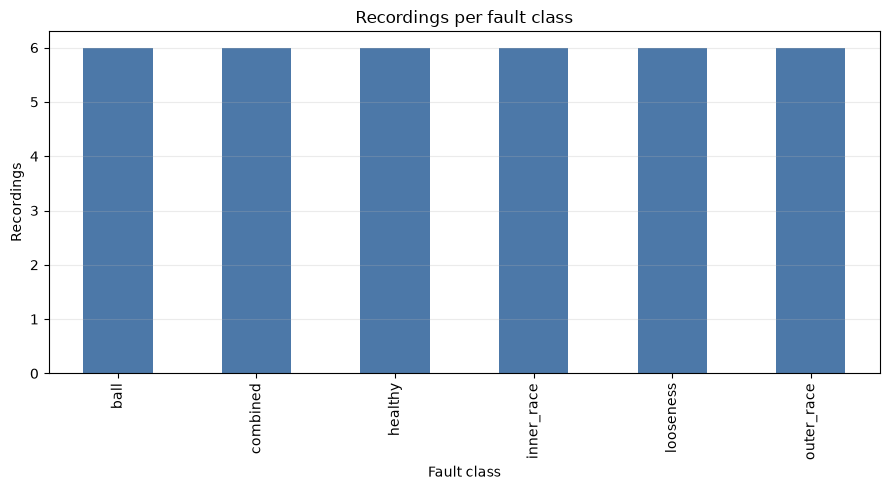

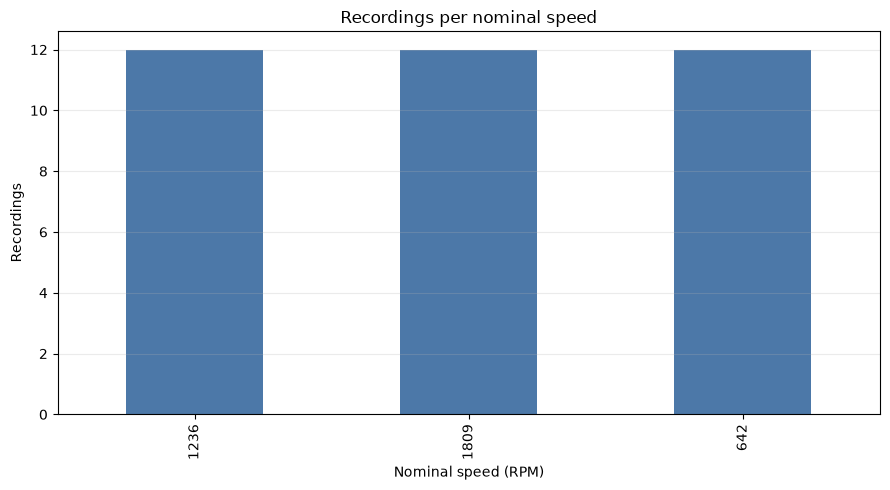

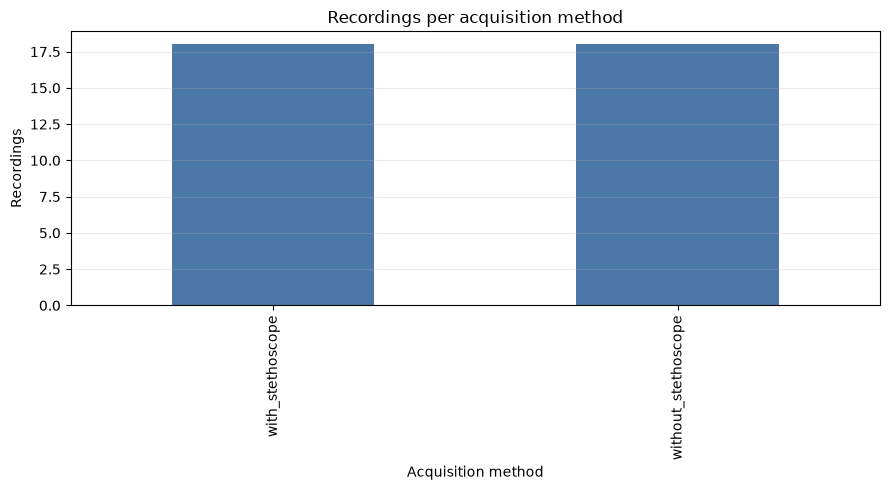

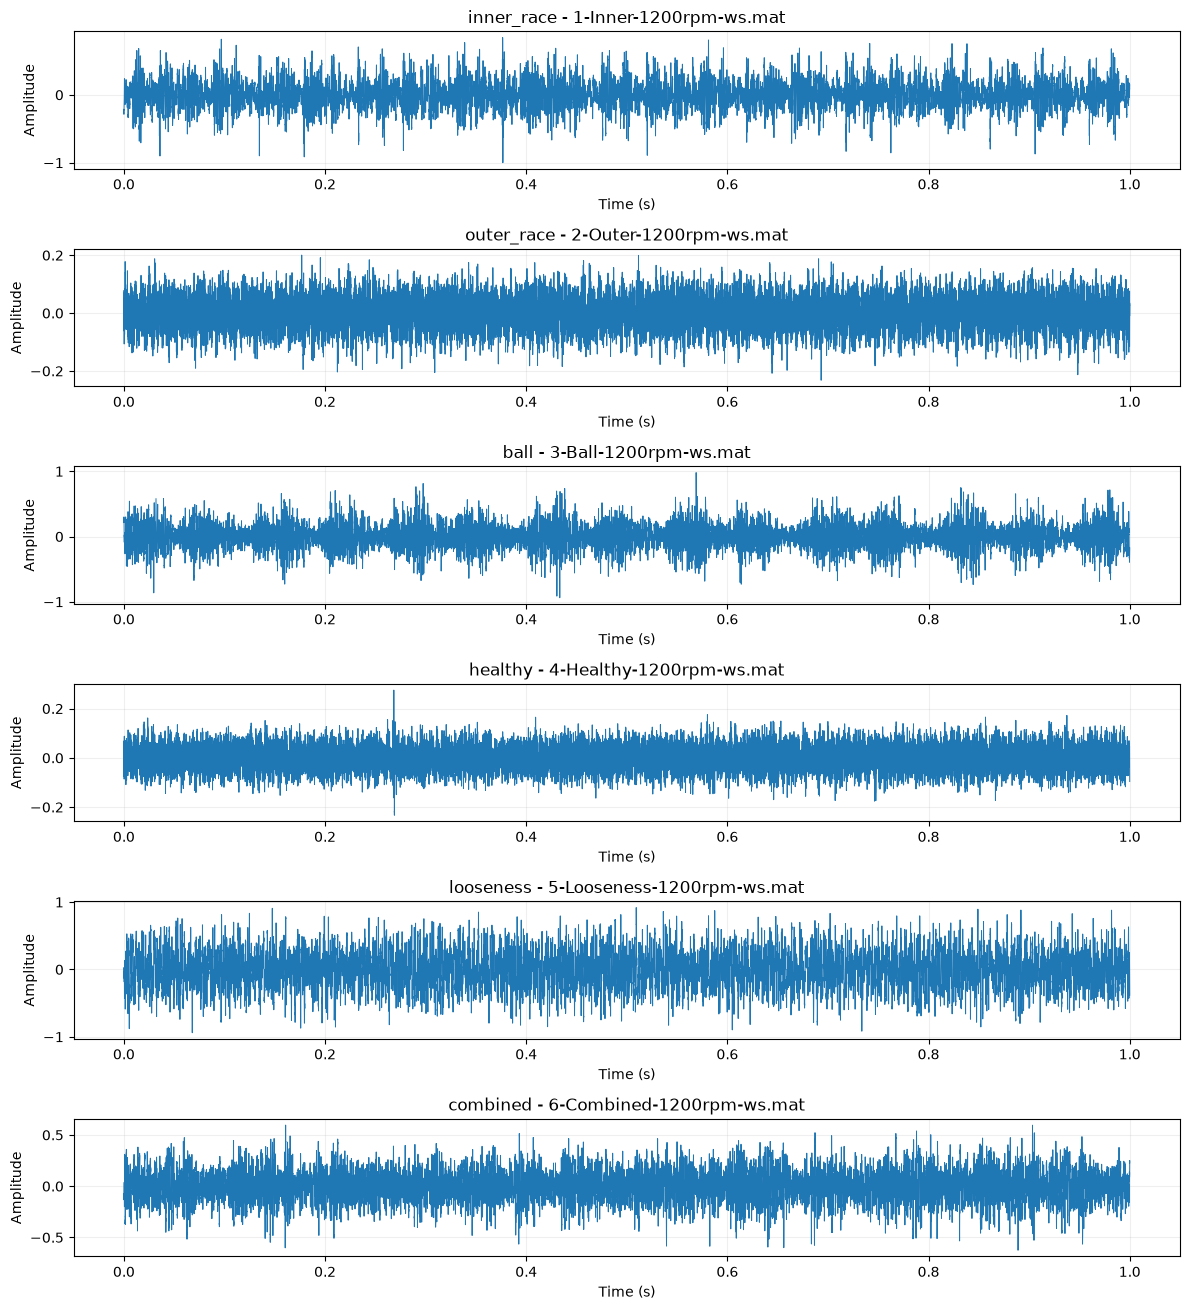

In [6]:
def save_bar(series, title, xlabel, ylabel, out_path):
    fig, ax = plt.subplots(figsize=(9, 5))
    series.plot(kind="bar", ax=ax, color="#4c78a8")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()


save_bar(recordings_df["fault"].value_counts().sort_index(), "Recordings per fault class", "Fault class", "Recordings", FIG_DIR / "recordings_per_fault.png")
save_bar(recordings_df["speed"].value_counts().sort_index(), "Recordings per nominal speed", "Nominal speed (RPM)", "Recordings", FIG_DIR / "recordings_per_speed.png")
save_bar(recordings_df["acquisition"].value_counts().sort_index(), "Recordings per acquisition method", "Acquisition method", "Recordings", FIG_DIR / "recordings_per_acquisition.png")

fault_examples = recordings_df.sort_values("filename").groupby("fault").head(1)
fig, axes = plt.subplots(len(fault_examples), 1, figsize=(12, 2.2 * len(fault_examples)), squeeze=False)
for ax, (_, row) in zip(axes[:, 0], fault_examples.iterrows()):
    loaded = load_mat_signal(row["filepath"])
    signal = loaded["signal"]
    sr = loaded["sample_rate"]
    n = min(len(signal), sr)
    t = np.arange(n) / sr
    ax.plot(t, signal[:n], linewidth=0.7)
    ax.set_title(f"{row['fault']} - {row['filename']}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_waveforms_by_fault.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Signal Segmentation

In [7]:
def build_segments(recordings: pd.DataFrame, segment_length: int, overlap: float) -> pd.DataFrame:
    hop = int(segment_length * (1.0 - overlap))
    if hop <= 0:
        raise ValueError("Overlap is too high; hop length must be positive.")

    rows = []
    max_segments = CONFIG["max_segments_per_recording"]
    for rec_idx, row in tqdm(list(recordings.reset_index(drop=True).iterrows()), desc="Building segment index"):
        total_samples = int(row["length_samples"])
        if total_samples < segment_length:
            continue
        starts = list(range(0, total_samples - segment_length + 1, hop))
        if max_segments > 0:
            starts = starts[:max_segments]
        for segment_id, start in enumerate(starts):
            rows.append(
                {
                    "recording_id": rec_idx,
                    "filepath": row["filepath"],
                    "filename": row["filename"],
                    "fault": row["fault"],
                    "speed": row["speed"],
                    "speed_rpm": row["speed_rpm"],
                    "acquisition": row["acquisition"],
                    "sample_rate": row["sample_rate"],
                    "signal_key": row["signal_key"],
                    "segment_id": segment_id,
                    "start_sample": int(start),
                    "end_sample": int(start + segment_length),
                }
            )
    return pd.DataFrame(rows)


segments_df = build_segments(recordings_df, CONFIG["segment_length"], CONFIG["overlap"])
if segments_df.empty:
    raise RuntimeError("No segments were created. Reduce segment_length or inspect recording durations.")

segments_df.to_csv(RESULTS_DIR / "segments_metadata.csv", index=False)
print(f"Window length: {CONFIG['segment_length']} samples. This captures local time-frequency structure while keeping CWT images computationally manageable.")
print(f"Created {len(segments_df)} segments from {segments_df['recording_id'].nunique()} recordings.")
display(segments_df.head())
display(segments_df.groupby("fault").size().reset_index(name="segments"))
display(segments_df.groupby("speed").size().reset_index(name="segments"))

Building segment index: 100%|██████████| 36/36 [00:00<00:00, 407.40it/s]

Window length: 4096 samples. This captures local time-frequency structure while keeping CWT images computationally manageable.
Created 11703 segments from 36 recordings.


,recording_id,filepath,filename,fault,speed,speed_rpm,acquisition,sample_rate,signal_key,segment_id,start_sample,end_sample
0,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,0,0,4096
1,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,1,2048,6144
2,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,2,4096,8192
3,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,3,6144,10240
4,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,4,8192,12288


,fault,segments
0,ball,2574
1,combined,1929
2,healthy,1476
3,inner_race,2574
4,looseness,1737
5,outer_race,1413


,speed,segments
0,1236,3901
1,1809,3901
2,642,3901


## 6. CWT Scalogram Generation

In [8]:
def scalogram_path(row: pd.Series) -> Path:
    stem = slugify(Path(row["filename"]).stem)
    return (
        SCALOGRAM_DIR
        / slugify(row["acquisition"])
        / slugify(row["speed"])
        / slugify(row["fault"])
        / f"{stem}_seg{int(row['segment_id']):05d}.png"
    )


def segment_to_scalogram(segment: np.ndarray, scales: np.ndarray, wavelet: str) -> np.ndarray:
    segment = segment.astype(np.float32, copy=False)
    segment = segment - np.mean(segment, dtype=np.float32)
    std = np.std(segment, dtype=np.float32)
    if std > 1e-8:
        segment = segment / std
    coeffs, _ = pywt.cwt(segment, scales, wavelet)
    power = np.abs(coeffs).astype(np.float32)
    power = np.log1p(power)
    lo, hi = np.percentile(power, [1, 99])
    power = np.clip((power - lo) / (hi - lo + 1e-8), 0, 1)
    gray = (power * 255).astype(np.uint8)
    return gray


def generate_scalograms(segments: pd.DataFrame) -> pd.DataFrame:
    segments = segments.copy()
    segments["image_path"] = segments.apply(lambda r: str(scalogram_path(r)), axis=1)
    missing = segments[~segments["image_path"].map(lambda p: Path(p).exists())]
    print(f"Total scalograms indexed: {len(segments)}")
    print(f"Already cached: {len(segments) - len(missing)}")
    print(f"To generate: {len(missing)}")

    errors = []
    for filepath, group in tqdm(missing.groupby("filepath"), total=missing["filepath"].nunique(), desc="Generating CWT by recording"):
        try:
            loaded = load_mat_signal(filepath)
            signal = loaded["signal"]
        except Exception as exc:
            errors.append({"filepath": filepath, "error": repr(exc)})
            continue

        for _, row in group.iterrows():
            out_path = Path(row["image_path"])
            if out_path.exists():
                continue
            try:
                segment = signal[int(row["start_sample"]):int(row["end_sample"])]
                image = segment_to_scalogram(segment, CONFIG["cwt_scales"], CONFIG["cwt_wavelet"])
                pil_image = Image.fromarray(image, mode="L").resize((CONFIG["image_size"], CONFIG["image_size"]), Image.Resampling.BICUBIC)
                out_path.parent.mkdir(parents=True, exist_ok=True)
                pil_image.save(out_path)
            except Exception as exc:
                errors.append({"filepath": filepath, "segment_id": int(row["segment_id"]), "error": repr(exc)})

    if errors:
        pd.DataFrame(errors).to_csv(LOG_DIR / "scalogram_generation_errors.csv", index=False)
        print(f"Logged {len(errors)} scalogram errors to {LOG_DIR / 'scalogram_generation_errors.csv'}")

    existing = segments[segments["image_path"].map(lambda p: Path(p).exists())].reset_index(drop=True)
    existing.to_csv(RESULTS_DIR / "scalograms_metadata.csv", index=False)
    print(f"Usable scalograms: {len(existing)}")
    return existing


scalograms_df = generate_scalograms(segments_df)
if scalograms_df.empty:
    raise RuntimeError("No scalogram images are available.")

display(scalograms_df.head())

Total scalograms indexed: 11703
Already cached: 0
To generate: 11703


Generating CWT by recording: 100%|██████████| 36/36 [08:56<00:00, 14.89s/it]

Usable scalograms: 11703


,recording_id,filepath,filename,fault,speed,speed_rpm,acquisition,sample_rate,signal_key,segment_id,start_sample,end_sample,image_path
0,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,0,0,4096,/home/arcues/Projects/IISA_2026/generated_scalograms/with_stethoscope/642/inner_race/first_speed_648_rpm_seg00000.png
1,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,1,2048,6144,/home/arcues/Projects/IISA_2026/generated_scalograms/with_stethoscope/642/inner_race/first_speed_648_rpm_seg00001.png
2,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,2,4096,8192,/home/arcues/Projects/IISA_2026/generated_scalograms/with_stethoscope/642/inner_race/first_speed_648_rpm_seg00002.png
3,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,3,6144,10240,/home/arcues/Projects/IISA_2026/generated_scalograms/with_stethoscope/642/inner_race/first_speed_648_rpm_seg00003.png
4,0,/home/arcues/Projects/IISA_2026/Sound Datasets of a Rolling Element Bearing under Various Operating Conditions/Datasets 1- Data acquisit...,First speed - 648 rpm.mat,inner_race,642,648,with_stethoscope,44100,x,4,8192,12288,/home/arcues/Projects/IISA_2026/generated_scalograms/with_stethoscope/642/inner_race/first_speed_648_rpm_seg00004.png


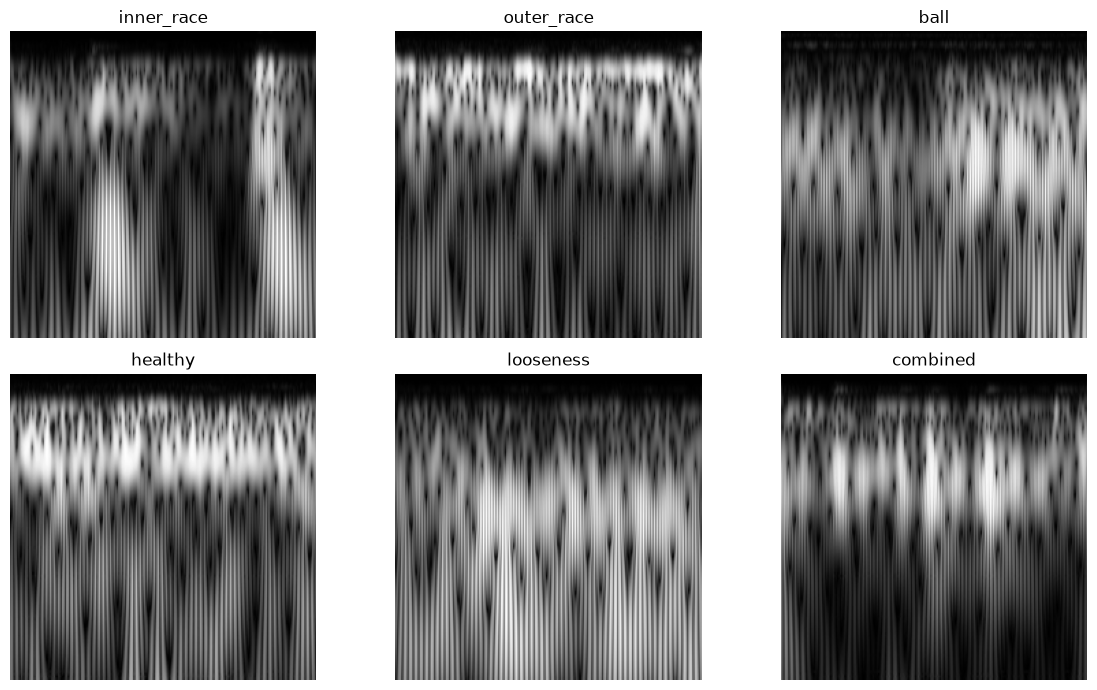

In [9]:
example_scalograms = scalograms_df.groupby("fault").head(1).reset_index(drop=True)
cols = min(3, len(example_scalograms))
rows = math.ceil(len(example_scalograms) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row) in zip(axes.ravel(), example_scalograms.iterrows()):
    ax.imshow(Image.open(row["image_path"]), cmap="gray")
    ax.set_title(row["fault"])
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_scalograms_by_fault.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. PyTorch Dataset

In [10]:
class CWTImageDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, class_to_idx: dict[str, int], transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, index: int):
        row = self.df.iloc[index]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        label = self.class_to_idx[row["fault"]]
        meta = {
            "image_path": row["image_path"],
            "fault": row["fault"],
            "speed": row["speed"],
            "acquisition": row["acquisition"],
            "filename": row["filename"],
        }
        return image, label, meta


classes = sorted(scalograms_df["fault"].unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_class = {idx: label for label, idx in class_to_idx.items()}
num_classes = len(classes)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])
train_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),
        scale=(0.98, 1.02),
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std,
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.01, 0.05),
        ratio=(0.5, 2.0),
    ),
])


def make_loader(df: pd.DataFrame, split: str, shuffle: bool = False) -> DataLoader:
    dataset = CWTImageDataset(df, class_to_idx=class_to_idx, transform=train_transform if split == "train" else eval_transform)
    return DataLoader(
        dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=shuffle,
        num_workers=CONFIG["num_workers"],
        pin_memory=(DEVICE.type == "cuda"),
    )


sample_loader = make_loader(scalograms_df.head(min(len(scalograms_df), CONFIG["batch_size"])), "test")
sample_images, sample_labels, sample_meta = next(iter(sample_loader))
print(f"Dataset size: {len(scalograms_df)}")
print(f"Class mapping: {class_to_idx}")
print(f"Sample batch image shape: {tuple(sample_images.shape)}")
print(f"Sample batch label shape: {tuple(sample_labels.shape)}")

Dataset size: 11703
Class mapping: {'ball': 0, 'combined': 1, 'healthy': 2, 'inner_race': 3, 'looseness': 4, 'outer_race': 5}
Sample batch image shape: (32, 3, 224, 224)
Sample batch label shape: (32,)


## 8. ResNet18 Model, Training, and Evaluation Utilities

In [11]:
def build_resnet18(num_classes: int) -> nn.Module:
    weights = None
    if os.environ.get("BEARING_USE_PRETRAINED", "1").lower() in {"1", "true", "yes"}:
        try:
            weights = models.ResNet18_Weights.DEFAULT
        except Exception:
            weights = None
    try:
        model = models.resnet18(weights=weights)
    except Exception as exc:
        print(f"Could not load pretrained ResNet18 weights ({exc}). Falling back to random initialization.")
        model = models.resnet18(weights=None)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, num_classes),
    )
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    for param in model.fc.parameters():
        param.requires_grad = True
    
    return model.to(DEVICE)


def move_batch_to_device(images, labels):
    return images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []
    for images, labels, _ in tqdm(loader, desc="Train", leave=False):
        images, labels = move_batch_to_device(images, labels)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())
    avg_loss = running_loss / max(1, len(loader.dataset))
    avg_f1 = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)[2]
    return avg_loss, avg_f1


@torch.no_grad()
def evaluate_loss_and_f1(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []
    for images, labels, _ in tqdm(loader, desc="Validate", leave=False):
        images, labels = move_batch_to_device(images, labels)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())
    avg_loss = running_loss / max(1, len(loader.dataset))
    avg_f1 = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)[2]
    return avg_loss, avg_f1


@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_labels, all_preds, all_probs, all_meta = [], [], [], []
    start_time = time.perf_counter()
    for images, labels, metas in tqdm(loader, desc="Predict", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        logits = model(images)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
        preds = probs.argmax(axis=1)
        all_probs.append(probs)
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().tolist())
        for i in range(len(labels)):
            all_meta.append({k: metas[k][i] for k in metas})
    elapsed = time.perf_counter() - start_time
    probs = np.vstack(all_probs) if all_probs else np.empty((0, num_classes))
    return np.array(all_labels), np.array(all_preds), probs, all_meta, elapsed


def compute_metrics(y_true, y_pred, y_prob):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),

        # Weighted metrics
        "weighted_precision": precision_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        ),
        "weighted_recall": recall_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        ),
        "weighted_f1": precision_recall_fscore_support(
            y_true, y_pred,
            average="weighted",
            zero_division=0,
        )[2],

        # Macro metrics
        "macro_precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": precision_recall_fscore_support(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        )[2],
    }

    try:
        if len(np.unique(y_true)) > 1 and y_prob.shape[1] == num_classes:
            y_true_bin = label_binarize(
                y_true,
                classes=list(range(num_classes))
            )
            metrics["roc_auc"] = roc_auc_score(
                y_true_bin,
                y_prob,
                average="weighted",
                multi_class="ovr",
            )
        else:
            metrics["roc_auc"] = np.nan
    except Exception:
        metrics["roc_auc"] = np.nan

    return metrics

In [12]:
def plot_training_history(history_df, experiment_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title(f"{experiment_name} loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(history_df["epoch"], history_df["train_f1"], label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_f1"], label="Validation")
    axes[1].set_title(f"{experiment_name} F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Weighted F1")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    out_path = RESULTS_DIR / "training_curves" / f"{slugify(experiment_name)}_training_curves.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def plot_confusion_matrix(y_true, y_pred, experiment_name):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(num_classes),
        yticks=np.arange(num_classes),
        xticklabels=classes,
        yticklabels=classes,
        ylabel="True label",
        xlabel="Predicted label",
        title=f"{experiment_name} confusion matrix",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0 if cm.max() else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    out_path = RESULTS_DIR / "confusion_matrices" / f"{slugify(experiment_name)}_confusion_matrix.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def plot_roc_curves(y_true, y_prob, experiment_name):
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))
    fig, ax = plt.subplots(figsize=(8, 7))
    for idx, class_name in enumerate(classes):
        if y_true_bin[:, idx].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_true_bin[:, idx], y_prob[:, idx])
        ax.plot(fpr, tpr, label=f"{class_name} AUC={auc(fpr, tpr):.2f}")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{experiment_name} ROC curves")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    out_path = RESULTS_DIR / "roc_curves" / f"{slugify(experiment_name)}_roc_curves.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    return out_path


def save_classification_report(y_true, y_pred, experiment_name):
    report = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T
    report_path = RESULTS_DIR / f"{slugify(experiment_name)}_classification_report.csv"
    report_df.to_csv(report_path)
    display(report_df)
    return report_df, report_path

In [13]:
def run_experiment(experiment_name, train_df, val_df, test_df):
    print(f"\n=== {experiment_name} ===")
    print(f"Train/Val/Test sizes: {len(train_df)} / {len(val_df)} / {len(test_df)}")
    display(pd.DataFrame({
        "train": train_df["fault"].value_counts(),
        "val": val_df["fault"].value_counts(),
        "test": test_df["fault"].value_counts(),
    }).fillna(0).astype(int))

    train_loader = make_loader(train_df, "train", shuffle=True)
    val_loader = make_loader(val_df, "val", shuffle=False)
    test_loader = make_loader(test_df, "test", shuffle=False)

    model = build_resnet18(num_classes)
    criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
    )
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    best_f1 = -np.inf
    best_epoch = -1
    patience_counter = 0
    history = []
    checkpoint_path = MODELS_DIR / f"best_resnet18_{slugify(experiment_name)}.pth"
    canonical_best_path = MODELS_DIR / "best_resnet18.pth"

    train_start = time.perf_counter()
    for epoch in range(1, CONFIG["epochs"] + 1):
        print(f"Epoch {epoch}/{CONFIG['epochs']}")
        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_f1 = evaluate_loss_and_f1(model, val_loader, criterion)
        scheduler.step(val_f1)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_f1": train_f1, "val_loss": val_loss, "val_f1": val_f1})
        print(f"train_loss={train_loss:.4f} train_f1={train_f1:.4f} val_loss={val_loss:.4f} val_f1={val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch
            patience_counter = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "class_to_idx": class_to_idx,
                    "config": {k: str(v) for k, v in CONFIG.items() if k != "cwt_scales"},
                    "experiment": experiment_name,
                    "best_val_f1": float(best_f1),
                },
                checkpoint_path,
            )
            shutil.copyfile(checkpoint_path, canonical_best_path)
        else:
            patience_counter += 1
            if patience_counter >= CONFIG["patience"]:
                print(f"Early stopping after epoch {epoch}. Best epoch: {best_epoch}")
                break

    training_time = time.perf_counter() - train_start
    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"{slugify(experiment_name)}_training_history.csv", index=False)
    plot_training_history(history_df, experiment_name)

    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])

    y_true, y_pred, y_prob, metas, inference_time = predict(model, test_loader)
    metrics = compute_metrics(y_true, y_pred, y_prob)
    metrics.update({
        "experiment": experiment_name,
        "training_time_sec": training_time,
        "inference_time_sec": inference_time,
        "best_epoch": best_epoch,
        "checkpoint": str(checkpoint_path),
    })

    plot_confusion_matrix(y_true, y_pred, experiment_name)
    if len(np.unique(y_true)) > 1:
        plot_roc_curves(y_true, y_prob, experiment_name)
    report_df, report_path = save_classification_report(y_true, y_pred, experiment_name)

    predictions_df = pd.DataFrame(metas)
    predictions_df["true_label"] = [idx_to_class[int(i)] for i in y_true]
    predictions_df["pred_label"] = [idx_to_class[int(i)] for i in y_pred]
    predictions_df["correct"] = predictions_df["true_label"] == predictions_df["pred_label"]
    predictions_df.to_csv(RESULTS_DIR / f"{slugify(experiment_name)}_predictions.csv", index=False)
    report_df["Experiment"] = experiment_name
    print(pd.Series(metrics))
    
    return {
        "model": model,
        "metrics": metrics,
        "history": history_df,
        "report": report_df,
        "predictions": predictions_df,
        "test_loader": test_loader,
        "test_df": test_df,
        "checkpoint_path": checkpoint_path,
    }

## 9. Experiment 1 - Within-Speed Classification



Fold 1/5
Unique recordings
-----------------
Train: 22
Validation: 6
Test: 8

Scalograms
----------
Train: 6923
Validation: 1929
Test: 2851

=== Within Speed Fold 1 ===
Train/Val/Test sizes: 6923 / 1929 / 2851


,train,val,test
fault,,,
ball,1716,429,429
combined,1072,214,643
healthy,984,214,278
inner_race,1287,429,858
looseness,1309,214,214
outer_race,555,429,429


Epoch 1/10


train_loss=0.6840 train_f1=0.8903 val_loss=1.3332 val_f1=0.5923
Epoch 2/10


train_loss=0.4768 train_f1=0.9862 val_loss=1.5702 val_f1=0.3784
Epoch 3/10


train_loss=0.4595 train_f1=0.9943 val_loss=1.6900 val_f1=0.3717
Epoch 4/10


train_loss=0.4469 train_f1=0.9959 val_loss=1.5780 val_f1=0.3805
Early stopping after epoch 4. Best epoch: 1


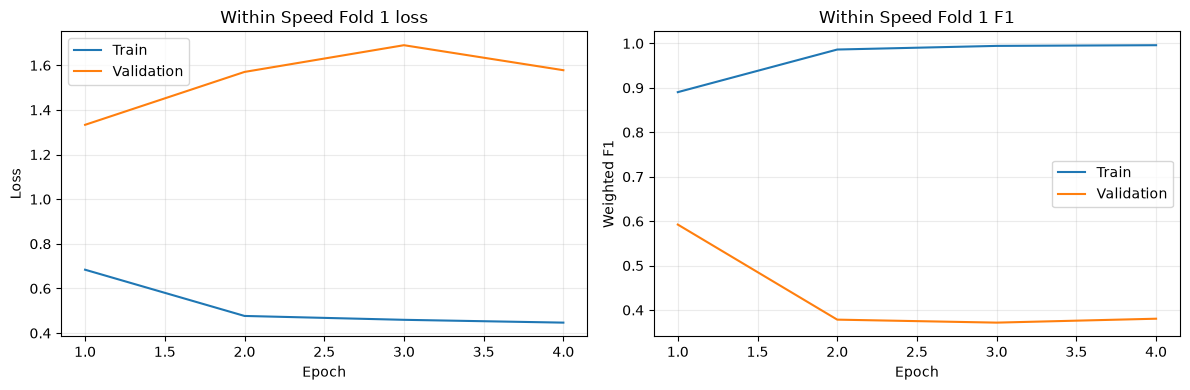

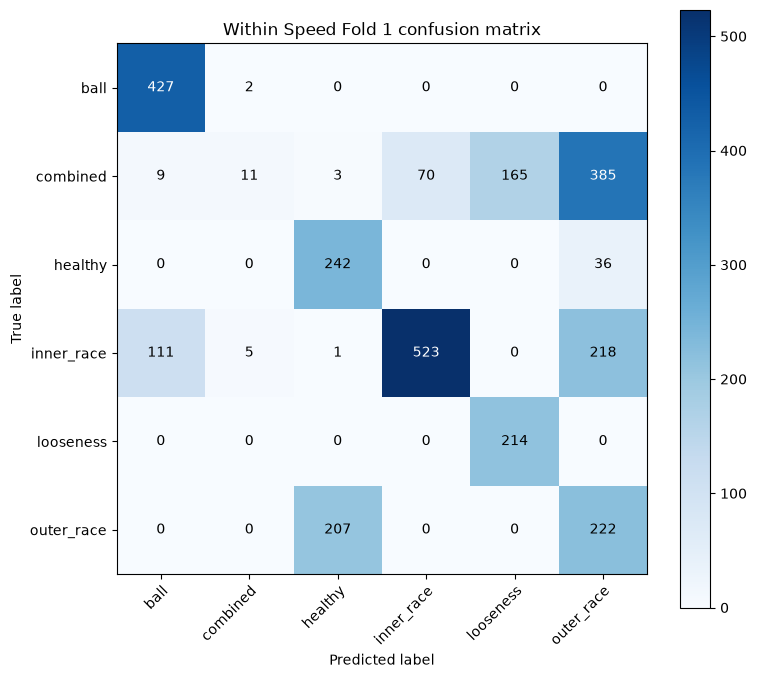

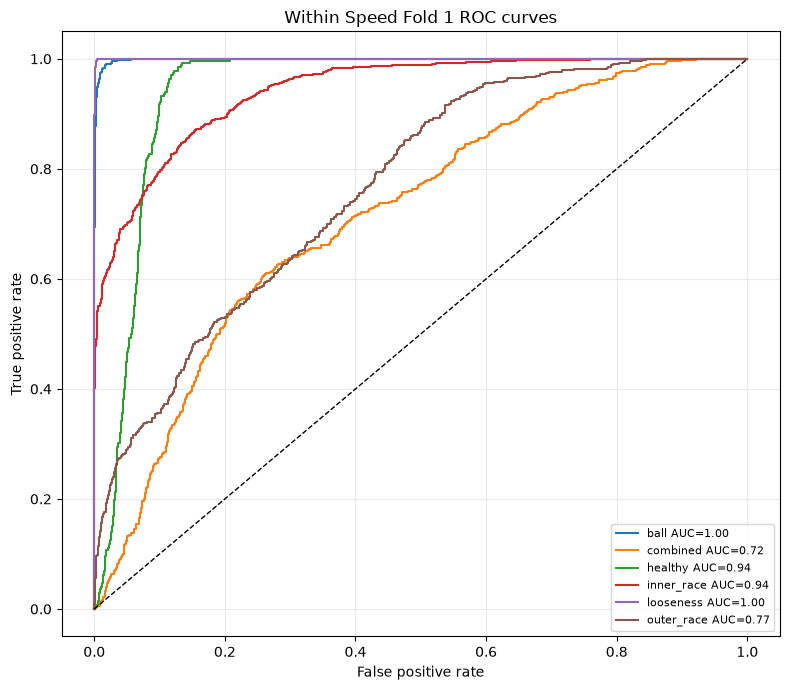

,precision,recall,f1-score,support
ball,0.780622,0.995338,0.875000,429.000000
combined,0.611111,0.017107,0.033283,643.000000
healthy,0.534216,0.870504,0.662107,278.000000
inner_race,0.881956,0.609557,0.720882,858.000000
looseness,0.564644,1.000000,0.721754,214.000000
outer_race,0.257840,0.517483,0.344186,429.000000
accuracy,0.574886,0.574886,0.574886,0.574886
macro avg,0.605065,0.668331,0.559535,2851.000000
weighted avg,0.653984,0.574886,0.526647,2851.000000


accuracy                                                                                  0.574886
weighted_precision                                                                        0.653984
weighted_recall                                                                           0.574886
weighted_f1                                                                               0.526647
macro_precision                                                                           0.605065
macro_recall                                                                              0.668331
macro_f1                                                                                  0.559535
roc_auc                                                                                   0.878241
experiment                                                                     Within Speed Fold 1
training_time_sec                                                                        91.850984
inference_

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,214,429
healthy,1048,214,214
inner_race,1716,429,429
looseness,1158,365,214
outer_race,900,42,471


Epoch 1/10


train_loss=0.6880 train_f1=0.8798 val_loss=1.0591 val_f1=0.5626
Epoch 2/10


train_loss=0.4736 train_f1=0.9908 val_loss=1.2214 val_f1=0.6069
Epoch 3/10


train_loss=0.4603 train_f1=0.9932 val_loss=1.2989 val_f1=0.6499
Epoch 4/10


train_loss=0.4524 train_f1=0.9952 val_loss=1.2512 val_f1=0.5812
Epoch 5/10


train_loss=0.4450 train_f1=0.9971 val_loss=1.2747 val_f1=0.5792
Epoch 6/10


train_loss=0.4406 train_f1=0.9979 val_loss=1.3319 val_f1=0.5806
Early stopping after epoch 6. Best epoch: 3


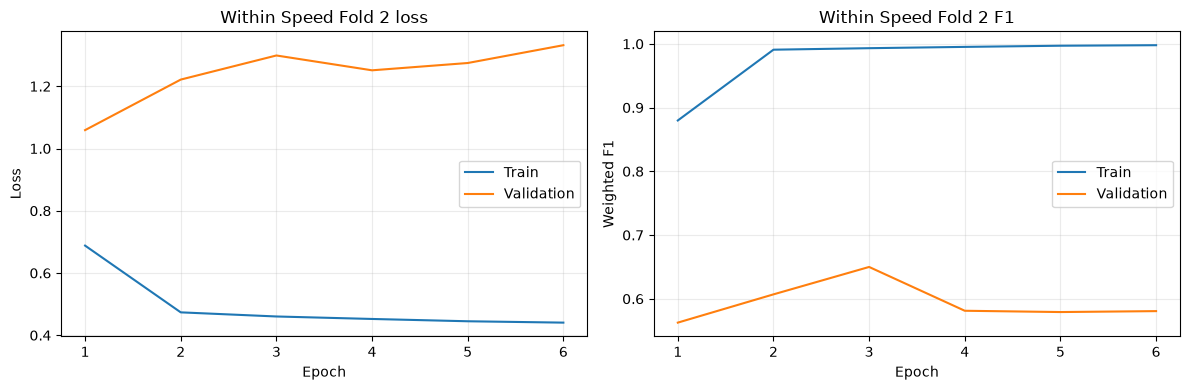

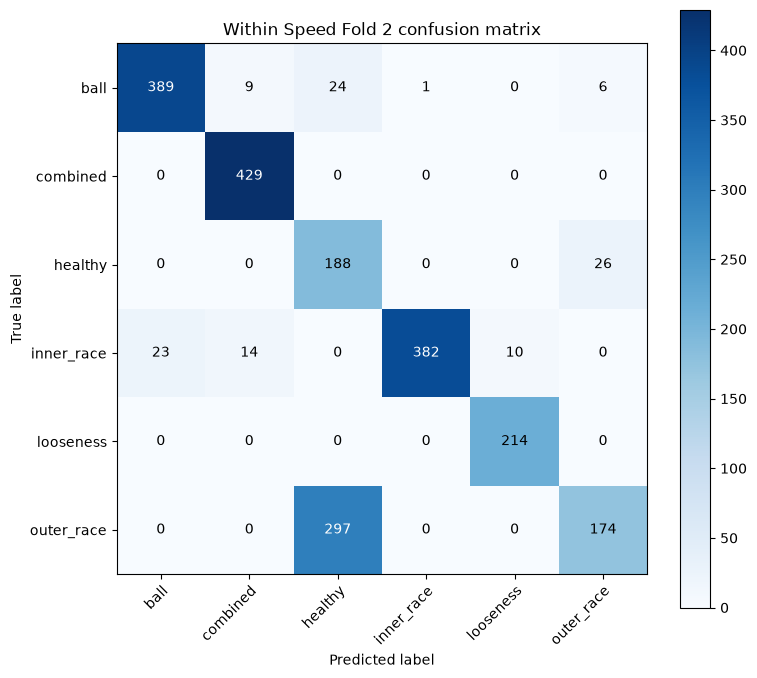

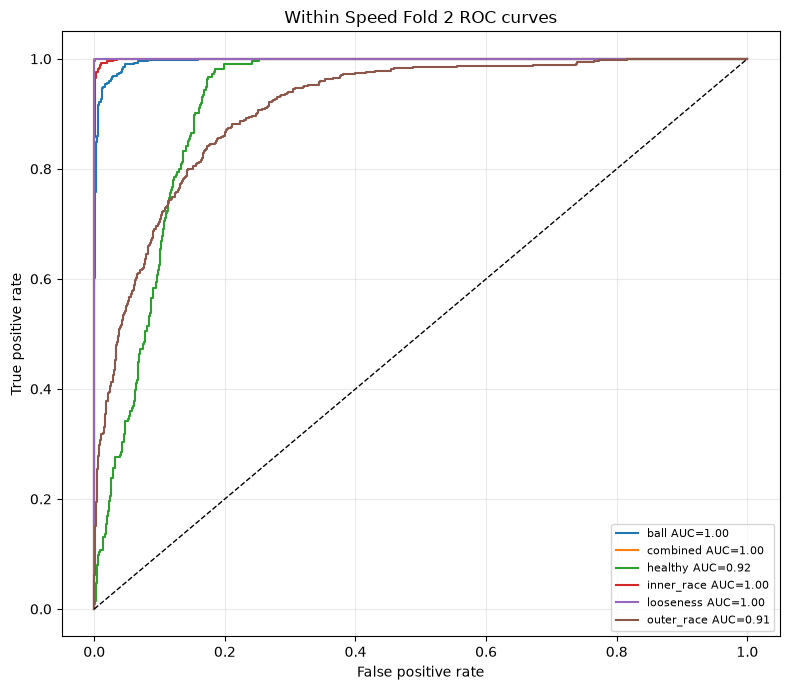

,precision,recall,f1-score,support
ball,0.944175,0.906760,0.925089,429.000000
combined,0.949115,1.000000,0.973893,429.000000
healthy,0.369352,0.878505,0.520055,214.000000
inner_race,0.997389,0.890443,0.940887,429.000000
looseness,0.955357,1.000000,0.977169,214.000000
outer_race,0.844660,0.369427,0.514032,471.000000
accuracy,0.812443,0.812443,0.812443,0.812443
macro avg,0.843341,0.840856,0.808521,2186.000000
weighted avg,0.878968,0.812443,0.814647,2186.000000


accuracy                                                                                  0.812443
weighted_precision                                                                        0.878968
weighted_recall                                                                           0.812443
weighted_f1                                                                               0.814647
macro_precision                                                                           0.843341
macro_recall                                                                              0.840856
macro_f1                                                                                  0.808521
roc_auc                                                                                   0.972383
experiment                                                                     Within Speed Fold 2
training_time_sec                                                                        150.42128
inference_

,train,val,test
fault,,,
ball,1287,429,858
combined,1286,429,214
healthy,984,278,214
inner_race,1716,429,429
looseness,1158,214,365
outer_race,942,42,429


Epoch 1/10


train_loss=0.6970 train_f1=0.8892 val_loss=0.9102 val_f1=0.6561
Epoch 2/10


train_loss=0.4716 train_f1=0.9937 val_loss=1.3232 val_f1=0.5956
Epoch 3/10


train_loss=0.4575 train_f1=0.9951 val_loss=1.1188 val_f1=0.6537
Epoch 4/10


train_loss=0.4445 train_f1=0.9984 val_loss=1.2622 val_f1=0.6168
Early stopping after epoch 4. Best epoch: 1


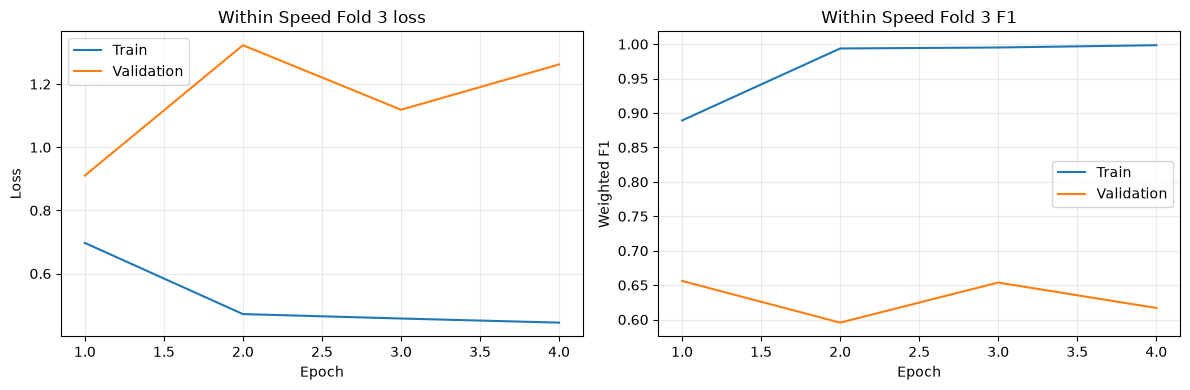

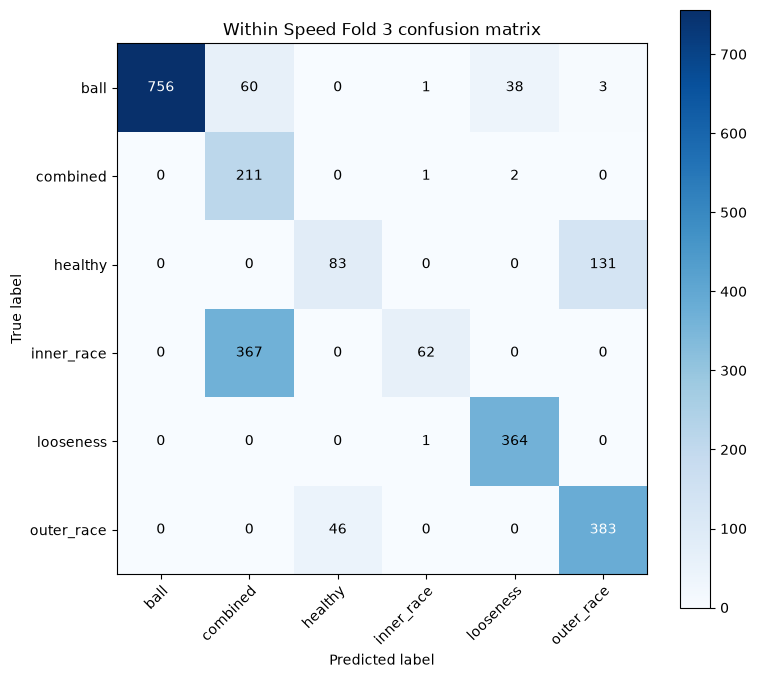

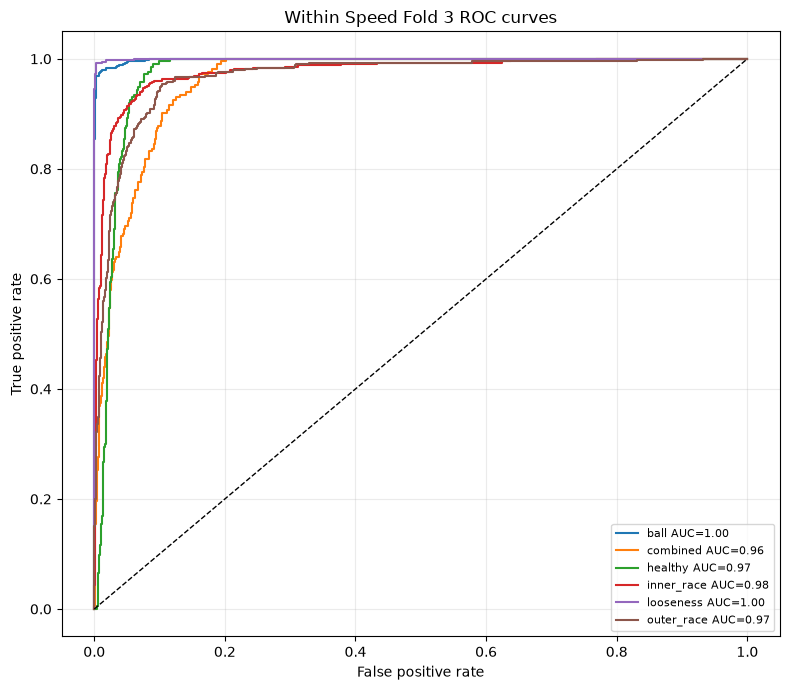

,precision,recall,f1-score,support
ball,1.000000,0.881119,0.936803,858.000000
combined,0.330721,0.985981,0.495305,214.000000
healthy,0.643411,0.387850,0.483965,214.000000
inner_race,0.953846,0.144522,0.251012,429.000000
looseness,0.900990,0.997260,0.946684,365.000000
outer_race,0.740812,0.892774,0.809725,429.000000
accuracy,0.740933,0.740933,0.740933,0.740933
macro avg,0.761630,0.714918,0.653916,2509.000000
weighted avg,0.845888,0.740933,0.722972,2509.000000


accuracy                                                                                  0.740933
weighted_precision                                                                        0.845888
weighted_recall                                                                           0.740933
weighted_f1                                                                               0.722972
macro_precision                                                                            0.76163
macro_recall                                                                              0.714918
macro_f1                                                                                  0.653916
roc_auc                                                                                   0.984319
experiment                                                                     Within Speed Fold 3
training_time_sec                                                                        94.109377
inference_

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,429,214
healthy,770,214,492
inner_race,1716,429,429
looseness,1309,214,214
outer_race,1329,42,42


Epoch 1/10


train_loss=0.6647 train_f1=0.9002 val_loss=0.9813 val_f1=0.6080
Epoch 2/10


train_loss=0.4687 train_f1=0.9918 val_loss=0.9946 val_f1=0.7086
Epoch 3/10


train_loss=0.4583 train_f1=0.9935 val_loss=0.9589 val_f1=0.6158
Epoch 4/10


train_loss=0.4494 train_f1=0.9960 val_loss=0.9453 val_f1=0.6465
Epoch 5/10


train_loss=0.4397 train_f1=0.9983 val_loss=0.8776 val_f1=0.6774
Early stopping after epoch 5. Best epoch: 2


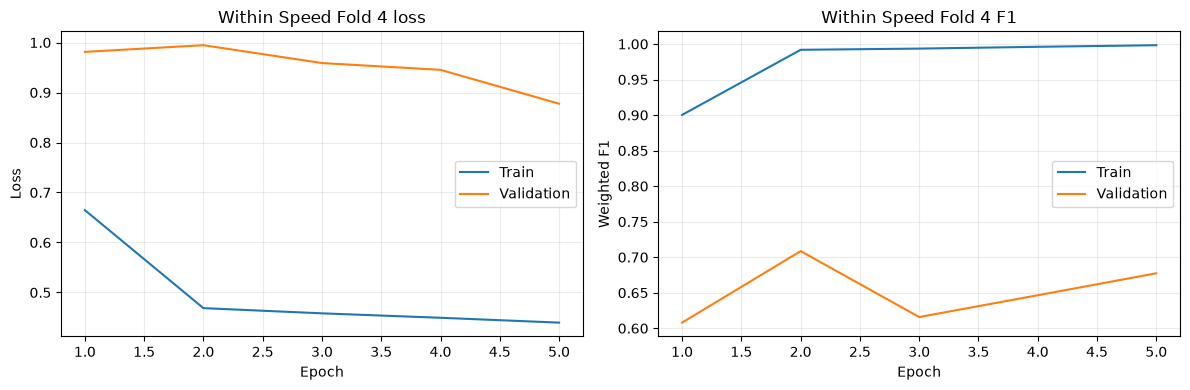

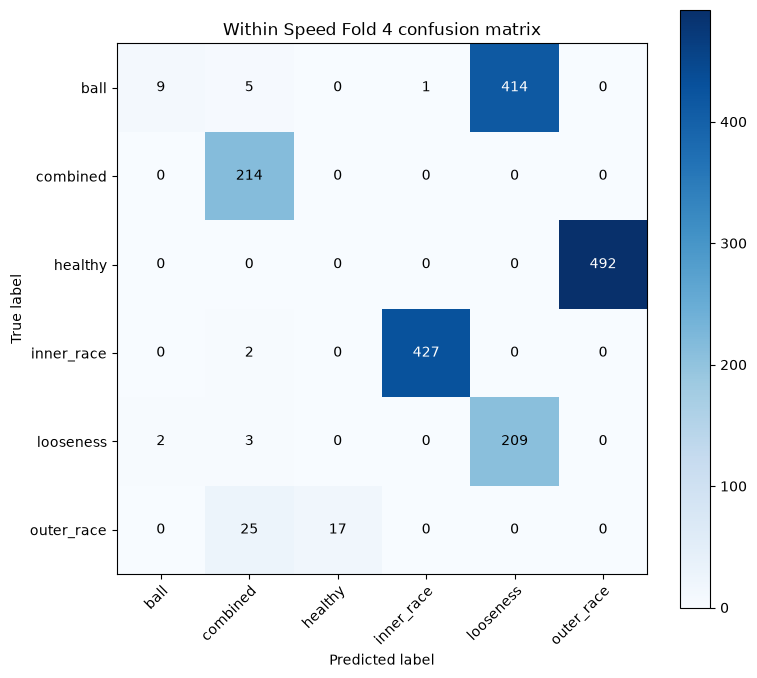

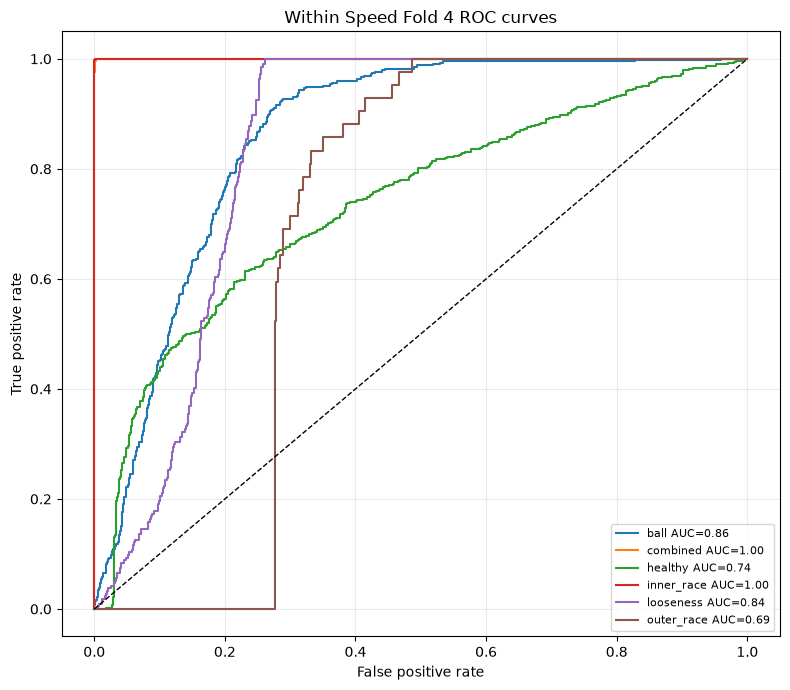

,precision,recall,f1-score,support
ball,0.818182,0.020979,0.040909,429.000000
combined,0.859438,1.000000,0.924406,214.000000
healthy,0.000000,0.000000,0.000000,492.000000
inner_race,0.997664,0.995338,0.996499,429.000000
looseness,0.335474,0.976636,0.499403,214.000000
outer_race,0.000000,0.000000,0.000000,42.000000
accuracy,0.471978,0.471978,0.471978,0.471978
macro avg,0.501793,0.498825,0.410203,1820.000000
weighted avg,0.568521,0.471978,0.411947,1820.000000


accuracy                                                                                  0.471978
weighted_precision                                                                        0.568521
weighted_recall                                                                           0.471978
weighted_f1                                                                               0.411947
macro_precision                                                                           0.501793
macro_recall                                                                              0.498825
macro_f1                                                                                  0.410203
roc_auc                                                                                   0.869893
experiment                                                                     Within Speed Fold 4
training_time_sec                                                                       126.507838
inference_

,train,val,test
fault,,,
ball,1716,429,429
combined,1286,214,429
healthy,984,214,278
inner_race,1716,429,429
looseness,793,214,730
outer_race,1329,42,42


Epoch 1/10


train_loss=0.7133 train_f1=0.8775 val_loss=1.5883 val_f1=0.3971
Epoch 2/10


train_loss=0.4793 train_f1=0.9906 val_loss=1.3788 val_f1=0.3987
Epoch 3/10


... (4 outputs left out)

train_loss=0.4372 train_f1=0.9990 val_loss=1.3178 val_f1=0.4286
Epoch 8/10


train_loss=0.4341 train_f1=0.9993 val_loss=1.5851 val_f1=0.3785
Epoch 9/10


train_loss=0.4329 train_f1=0.9994 val_loss=1.4083 val_f1=0.4059
Epoch 10/10


train_loss=0.4320 train_f1=0.9996 val_loss=1.4355 val_f1=0.4354


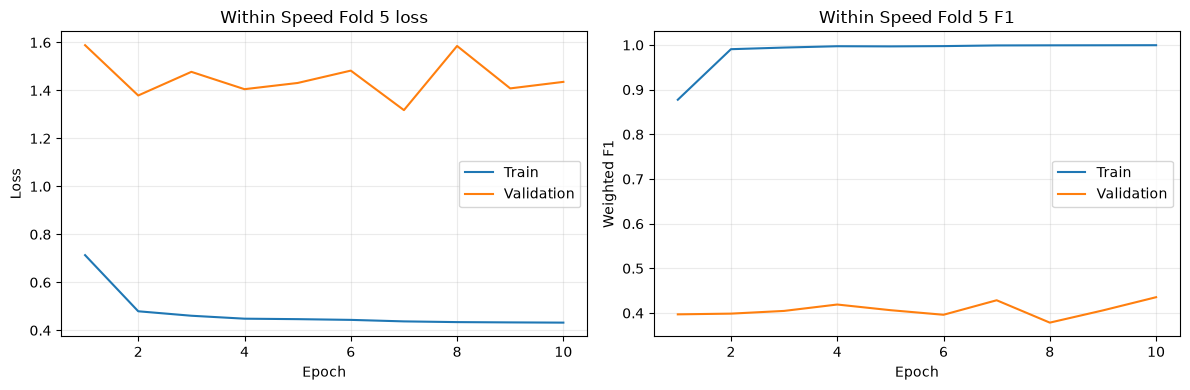

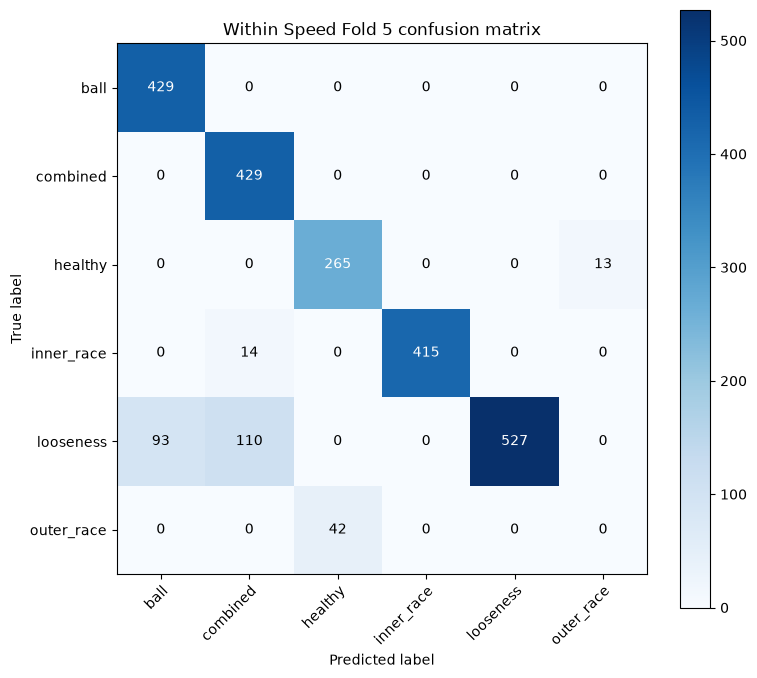

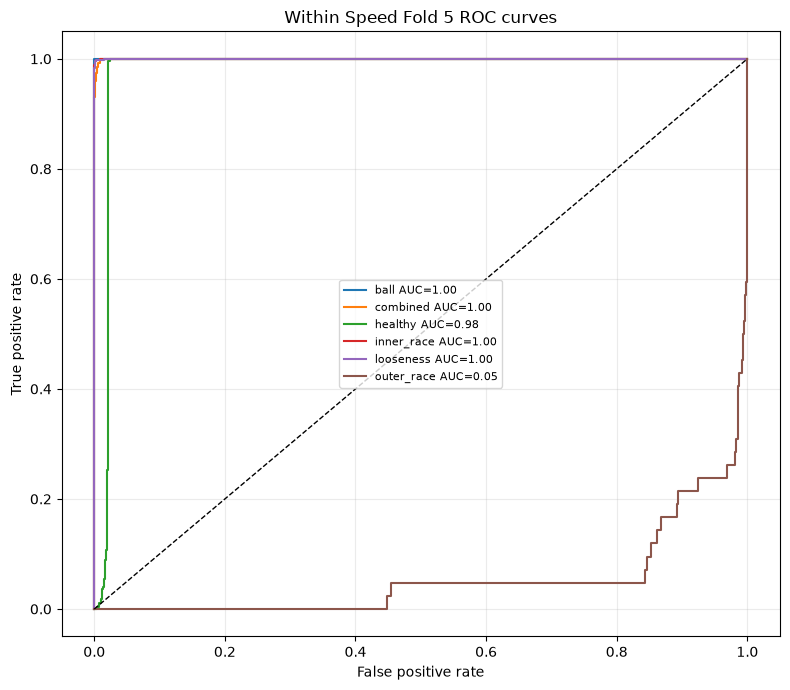

,precision,recall,f1-score,support
ball,0.821839,1.000000,0.902208,429.000000
combined,0.775769,1.000000,0.873727,429.000000
healthy,0.863192,0.953237,0.905983,278.000000
inner_race,1.000000,0.967366,0.983412,429.000000
looseness,1.000000,0.721918,0.838504,730.000000
outer_race,0.000000,0.000000,0.000000,42.000000
accuracy,0.883611,0.883611,0.883611,0.883611
macro avg,0.743467,0.773754,0.750639,2337.000000
weighted avg,0.891888,0.883611,0.876222,2337.000000


accuracy                                                                                  0.883611
weighted_precision                                                                        0.891888
weighted_recall                                                                           0.883611
weighted_f1                                                                               0.876222
macro_precision                                                                           0.743467
macro_recall                                                                              0.773754
macro_f1                                                                                  0.750639
roc_auc                                                                                   0.980614
experiment                                                                     Within Speed Fold 5
training_time_sec                                                                       242.822559
inference_

,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1,roc_auc,experiment,training_time_sec,inference_time_sec,best_epoch,checkpoint
0,0.574886,0.653984,0.574886,0.526647,0.605065,0.668331,0.559535,0.878241,Within Speed Fold 1,91.850984,6.133265,1,/home/arcues/Projects/IISA_2026/models/best_resnet18_within_speed_fold_1.pth
1,0.812443,0.878968,0.812443,0.814647,0.843341,0.840856,0.808521,0.972383,Within Speed Fold 2,150.421280,4.598825,3,/home/arcues/Projects/IISA_2026/models/best_resnet18_within_speed_fold_2.pth
2,0.740933,0.845888,0.740933,0.722972,0.761630,0.714918,0.653916,0.984319,Within Speed Fold 3,94.109377,5.294117,1,/home/arcues/Projects/IISA_2026/models/best_resnet18_within_speed_fold_3.pth
3,0.471978,0.568521,0.471978,0.411947,0.501793,0.498825,0.410203,0.869893,Within Speed Fold 4,126.507838,3.829464,2,/home/arcues/Projects/IISA_2026/models/best_resnet18_within_speed_fold_4.pth
4,0.883611,0.891888,0.883611,0.876222,0.743467,0.773754,0.750639,0.980614,Within Speed Fold 5,242.822559,4.861825,10,/home/arcues/Projects/IISA_2026/models/best_resnet18_within_speed_fold_5.pth




5-FOLD CROSS VALIDATION RESULTS


,Mean,Std
accuracy,0.696770,0.170020
weighted_precision,0.767850,0.147071
weighted_recall,0.696770,0.170020
weighted_f1,0.670487,0.195830
macro_precision,0.691059,0.136137
macro_recall,0.699337,0.129397
macro_f1,0.636563,0.158158
roc_auc,0.937090,0.057769
training_time_sec,141.142407,61.807912
inference_time_sec,4.943499,0.852206


In [22]:
# ==========================================================
# 5-Fold Stratified Cross Validation (recording-level)
# ==========================================================

recordings = (
    scalograms_df[["recording_id", "fault"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

all_fold_metrics = []
all_fold_reports = []
all_fold_results = []

for fold, (train_index, test_index) in enumerate(
    skf.split(recordings["recording_id"], recordings["fault"]),
    start=1,
):

    print("\n")
    print("=" * 70)
    print(f"Fold {fold}/5")
    print("=" * 70)

    train_rec = recordings.iloc[train_index].reset_index(drop=True)
    test_rec = recordings.iloc[test_index].reset_index(drop=True)

    #
    # Create validation recordings from training recordings
    #

    train_rec, val_rec = train_test_split(
        train_rec,
        test_size=0.2,
        random_state=SEED,
        stratify=train_rec["fault"],
    )

    train_df = scalograms_df[
        scalograms_df["recording_id"].isin(train_rec["recording_id"])
    ].reset_index(drop=True)

    val_df = scalograms_df[
        scalograms_df["recording_id"].isin(val_rec["recording_id"])
    ].reset_index(drop=True)

    test_df = scalograms_df[
        scalograms_df["recording_id"].isin(test_rec["recording_id"])
    ].reset_index(drop=True)

    #
    # Leakage check
    #

    assert (
        set(train_df.recording_id)
        & set(val_df.recording_id)
    ) == set()

    assert (
        set(train_df.recording_id)
        & set(test_df.recording_id)
    ) == set()

    assert (
        set(val_df.recording_id)
        & set(test_df.recording_id)
    ) == set()

    #
    # Statistics
    #

    print("Unique recordings")
    print("-----------------")
    print("Train:", train_df.recording_id.nunique())
    print("Validation:", val_df.recording_id.nunique())
    print("Test:", test_df.recording_id.nunique())

    print()

    print("Scalograms")
    print("----------")
    print("Train:", len(train_df))
    print("Validation:", len(val_df))
    print("Test:", len(test_df))

    #
    # Train
    #

    result = run_experiment(
        f"Within Speed Fold {fold}",
        train_df,
        val_df,
        test_df,
    )

    all_fold_metrics.append(result["metrics"])
    all_fold_reports.append(result["report"])
    all_fold_results.append(result)

#
# ==========================================================
# Cross-validation summary
# ==========================================================
#

results_df = pd.DataFrame(all_fold_metrics)

display(results_df)

print("\n")
print("=" * 60)
print("5-FOLD CROSS VALIDATION RESULTS")
print("=" * 60)

numeric_cols = results_df.select_dtypes(include=np.number).columns

summary = pd.DataFrame({
    "Mean": results_df[numeric_cols].mean(),
    "Std": results_df[numeric_cols].std()
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "within_speed_cross_validation_summary.csv"
)

results_df.to_csv(
    RESULTS_DIR / "within_speed_fold_results.csv",
    index=False,
)


## 10. Experiment 2 - Cross-Speed Generalization


Cross-Speed Stratified 4-Fold Summary

Fold 1
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5981
Validation scalograms : 1821
Test scalograms : 3901

Fold 2
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5443
Validation scalograms : 2359
Test scalograms : 3901

Fold 3
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 6109
Validation scalograms : 1693
Test scalograms : 3901

Fold 4
--------------------------
Train recordings : 18
Validation recordings : 6
Test recordings : 12
Train scalograms : 5873
Validation scalograms : 1929
Test scalograms : 3901


Cross-Speed Fold 1

=== Cross Speed Fold 1 ===
Train/Val/Test sizes: 5981 / 1821 / 3901


,train,val,test
fault,,,
ball,1287,429,858
combined,857,429,643
healthy,706,278,492
inner_race,1287,429,858
looseness,944,214,579
outer_race,900,42,471


Epoch 1/10


train_loss=0.7180 train_f1=0.8779 val_loss=1.4768 val_f1=0.4036
Epoch 2/10


train_loss=0.4918 train_f1=0.9885 val_loss=1.3526 val_f1=0.4840
Epoch 3/10


train_loss=0.4678 train_f1=0.9936 val_loss=1.4052 val_f1=0.4342
Epoch 4/10


train_loss=0.4544 train_f1=0.9969 val_loss=1.3830 val_f1=0.4233
Epoch 5/10


train_loss=0.4510 train_f1=0.9978 val_loss=1.3619 val_f1=0.4557
Early stopping after epoch 5. Best epoch: 2


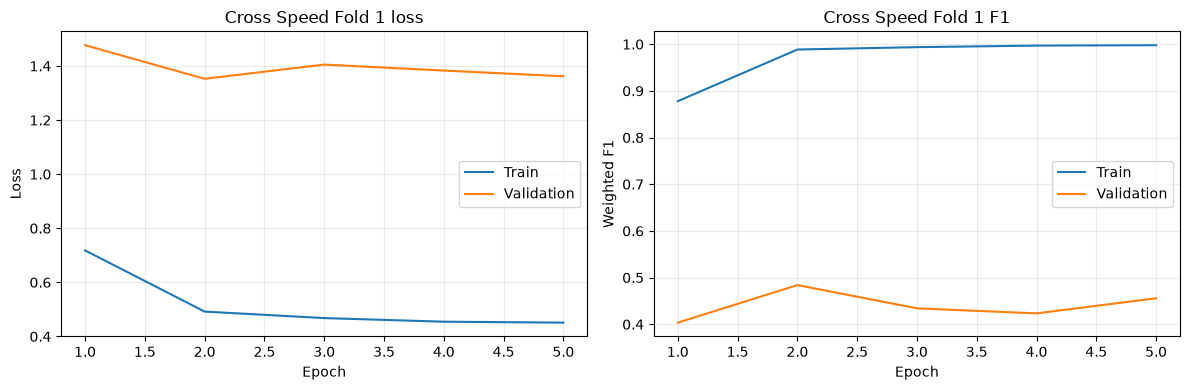

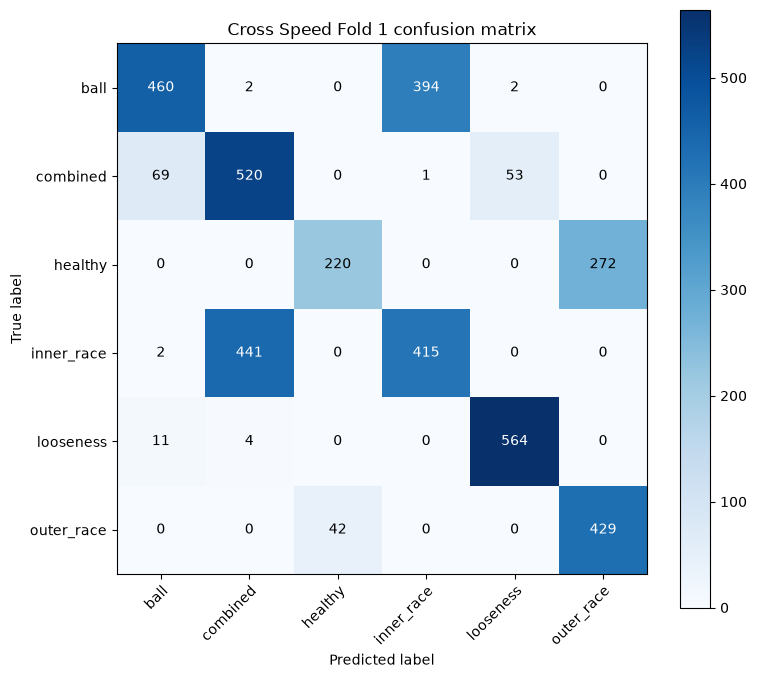

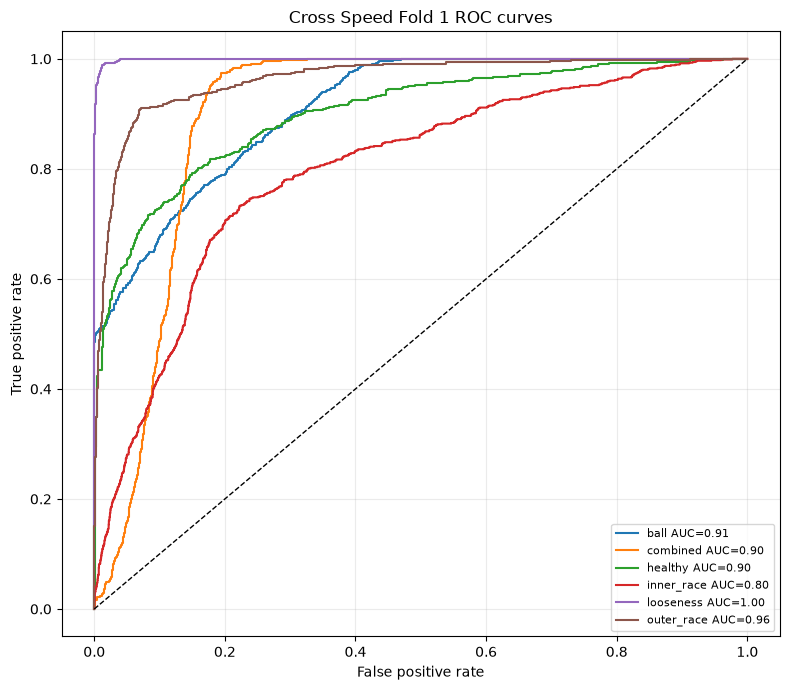

,precision,recall,f1-score,support
ball,0.848708,0.536131,0.657143,858.000000
combined,0.537746,0.808709,0.645963,643.000000
healthy,0.839695,0.447154,0.583554,492.000000
inner_race,0.512346,0.483683,0.497602,858.000000
looseness,0.911147,0.974093,0.941569,579.000000
outer_race,0.611983,0.910828,0.732082,471.000000
accuracy,0.668547,0.668547,0.668547,0.668547
macro avg,0.710271,0.693433,0.676319,3901.000000
weighted avg,0.703020,0.668547,0.662193,3901.000000


accuracy                                                                                 0.668547
weighted_precision                                                                        0.70302
weighted_recall                                                                          0.668547
weighted_f1                                                                              0.662193
macro_precision                                                                          0.710271
macro_recall                                                                             0.693433
macro_f1                                                                                 0.676319
roc_auc                                                                                  0.901675
experiment                                                                     Cross Speed Fold 1
training_time_sec                                                                       98.308975
inference_time_sec  

,train,val,test
fault,,,
ball,1287,429,858
combined,857,429,643
healthy,706,278,492
inner_race,1287,429,858
looseness,793,365,579
outer_race,513,429,471


Epoch 1/10


train_loss=0.7015 train_f1=0.8792 val_loss=0.9830 val_f1=0.7133
Epoch 2/10


train_loss=0.4892 train_f1=0.9861 val_loss=0.9740 val_f1=0.6731
Epoch 3/10


train_loss=0.4621 train_f1=0.9948 val_loss=0.8330 val_f1=0.8242
Epoch 4/10


train_loss=0.4636 train_f1=0.9898 val_loss=0.9405 val_f1=0.6931
Epoch 5/10


train_loss=0.4508 train_f1=0.9954 val_loss=0.8461 val_f1=0.8094
Epoch 6/10


train_loss=0.4483 train_f1=0.9961 val_loss=0.8777 val_f1=0.7717
Early stopping after epoch 6. Best epoch: 3


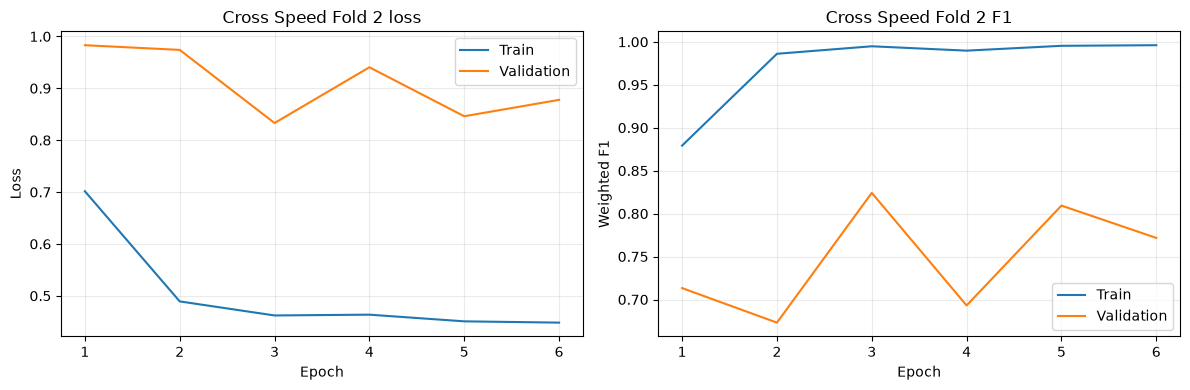

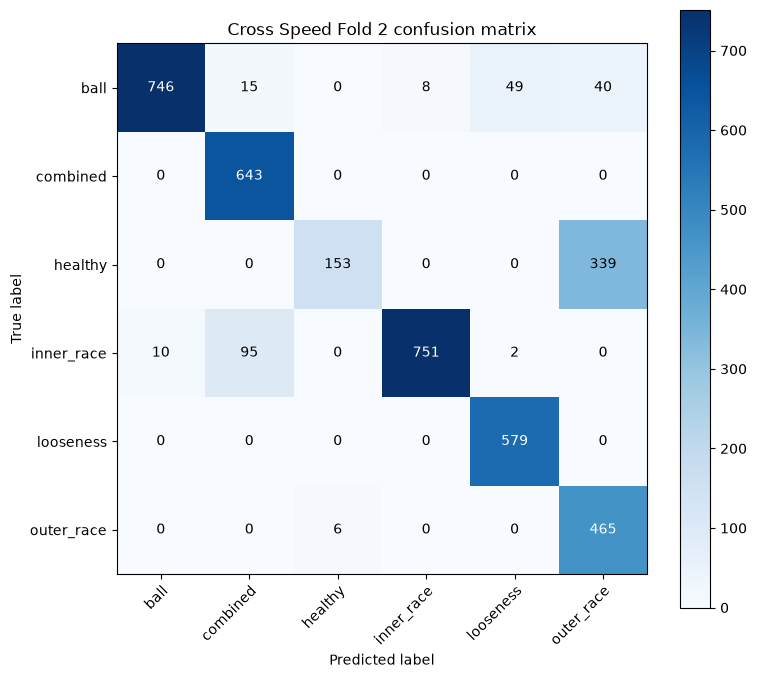

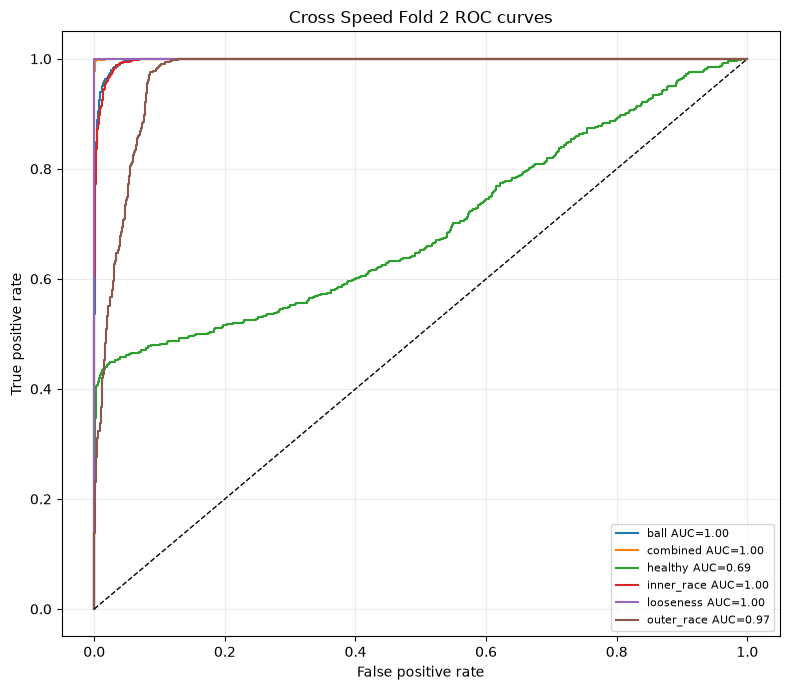

,precision,recall,f1-score,support
ball,0.986772,0.869464,0.924411,858.000000
combined,0.853918,1.000000,0.921203,643.000000
healthy,0.962264,0.310976,0.470046,492.000000
inner_race,0.989460,0.875291,0.928881,858.000000
looseness,0.919048,1.000000,0.957816,579.000000
outer_race,0.550948,0.987261,0.707224,471.000000
accuracy,0.855422,0.855422,0.855422,0.855422
macro avg,0.877068,0.840499,0.818264,3901.000000
weighted avg,0.899701,0.855422,0.846296,3901.000000


accuracy                                                                                 0.855422
weighted_precision                                                                       0.899701
weighted_recall                                                                          0.855422
weighted_f1                                                                              0.846296
macro_precision                                                                          0.877068
macro_recall                                                                             0.840499
macro_f1                                                                                 0.818264
roc_auc                                                                                  0.956692
experiment                                                                     Cross Speed Fold 2
training_time_sec                                                                      116.049439
inference_time_sec  

,train,val,test
fault,,,
ball,1287,429,858
combined,1072,214,643
healthy,770,214,492
inner_race,1287,429,858
looseness,793,365,579
outer_race,900,42,471


Epoch 1/10


train_loss=0.7306 train_f1=0.8694 val_loss=1.0442 val_f1=0.6261
Epoch 2/10


train_loss=0.4901 train_f1=0.9870 val_loss=1.0534 val_f1=0.5763
Epoch 3/10


train_loss=0.4637 train_f1=0.9944 val_loss=1.0789 val_f1=0.5387
Epoch 4/10


train_loss=0.4559 train_f1=0.9947 val_loss=1.1260 val_f1=0.4918
Early stopping after epoch 4. Best epoch: 1


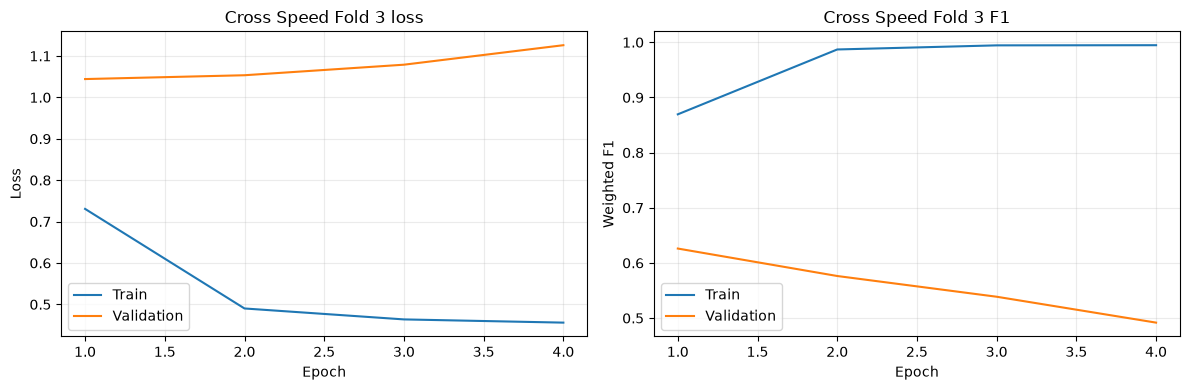

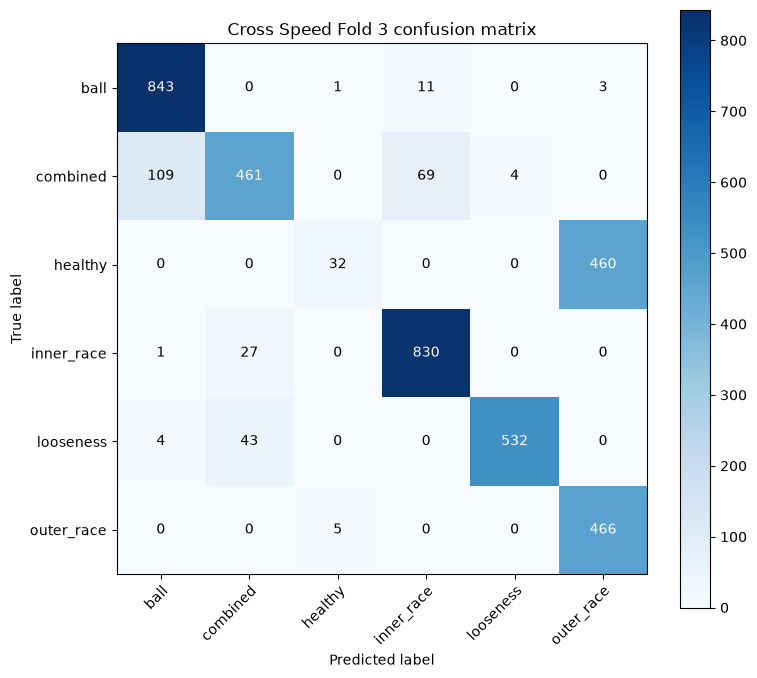

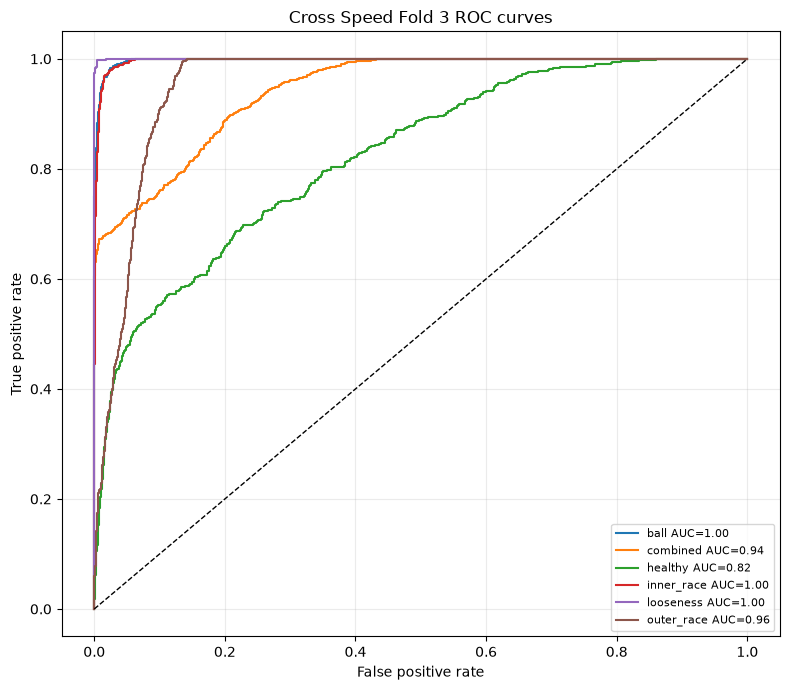

,precision,recall,f1-score,support
ball,0.880878,0.982517,0.928926,858.000000
combined,0.868173,0.716952,0.785349,643.000000
healthy,0.842105,0.065041,0.120755,492.000000
inner_race,0.912088,0.967366,0.938914,858.000000
looseness,0.992537,0.918826,0.954260,579.000000
outer_race,0.501615,0.989384,0.665714,471.000000
accuracy,0.811074,0.811074,0.811074,0.811074
macro avg,0.832899,0.773348,0.732320,3901.000000
weighted avg,0.851539,0.811074,0.777510,3901.000000


accuracy                                                                                 0.811074
weighted_precision                                                                       0.851539
weighted_recall                                                                          0.811074
weighted_f1                                                                               0.77751
macro_precision                                                                          0.832899
macro_recall                                                                             0.773348
macro_f1                                                                                  0.73232
roc_auc                                                                                  0.961736
experiment                                                                     Cross Speed Fold 3
training_time_sec                                                                       78.493457
inference_time_sec  

,train,val,test
fault,,,
ball,1287,429,858
combined,1072,214,643
healthy,770,214,492
inner_race,1287,429,858
looseness,944,214,579
outer_race,513,429,471


Epoch 1/10


train_loss=0.7489 train_f1=0.8541 val_loss=1.0211 val_f1=0.5906
Epoch 2/10


train_loss=0.4874 train_f1=0.9891 val_loss=0.9057 val_f1=0.6754
Epoch 3/10


train_loss=0.4710 train_f1=0.9927 val_loss=0.9261 val_f1=0.6728
Epoch 4/10


train_loss=0.4578 train_f1=0.9944 val_loss=1.0932 val_f1=0.5549
Epoch 5/10


train_loss=0.4503 train_f1=0.9967 val_loss=1.0307 val_f1=0.6228
Early stopping after epoch 5. Best epoch: 2


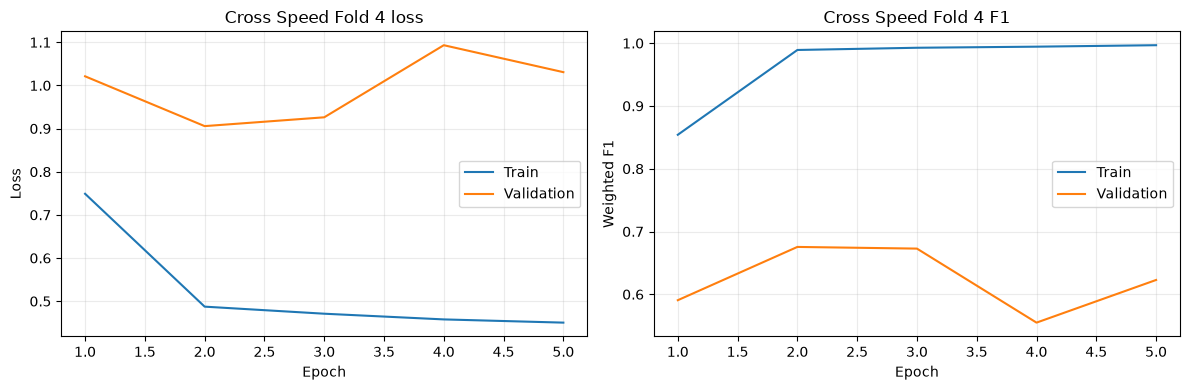

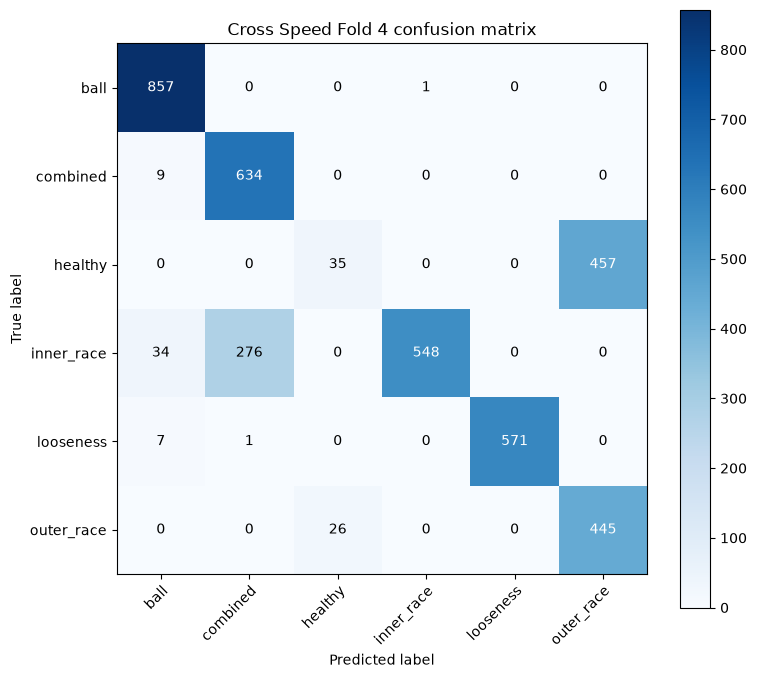

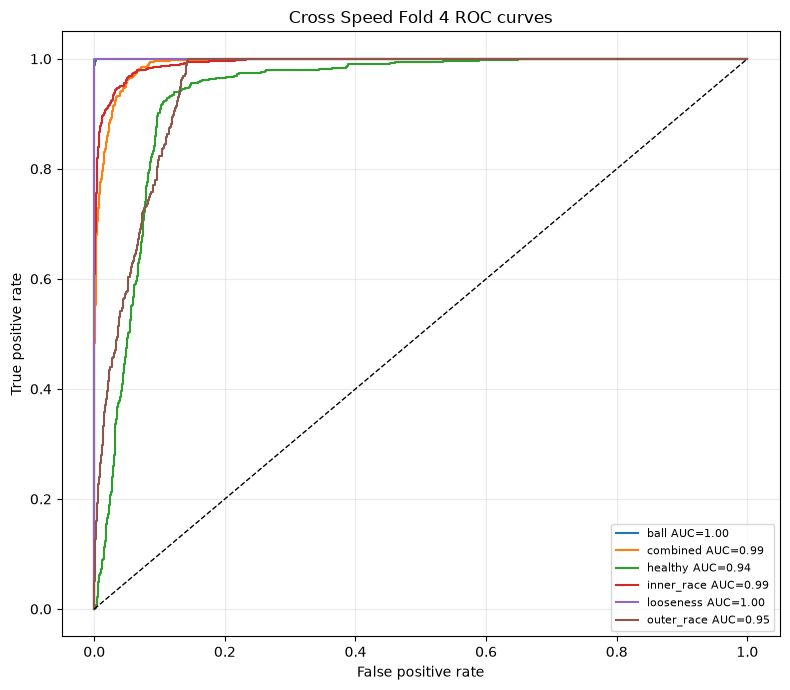

,precision,recall,f1-score,support
ball,0.944873,0.998834,0.971105,858.000000
combined,0.695939,0.986003,0.815959,643.000000
healthy,0.573770,0.071138,0.126582,492.000000
inner_race,0.998179,0.638695,0.778962,858.000000
looseness,1.000000,0.986183,0.993043,579.000000
outer_race,0.493348,0.944798,0.648216,471.000000
accuracy,0.792105,0.792105,0.792105,0.792105
macro avg,0.784351,0.770942,0.722311,3901.000000
weighted avg,0.822427,0.792105,0.761030,3901.000000


accuracy                                                                                 0.792105
weighted_precision                                                                       0.822427
weighted_recall                                                                          0.792105
weighted_f1                                                                               0.76103
macro_precision                                                                          0.784351
macro_recall                                                                             0.770942
macro_f1                                                                                 0.722311
roc_auc                                                                                  0.982967
experiment                                                                     Cross Speed Fold 4
training_time_sec                                                                       97.352729
inference_time_sec  

,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_precision,macro_recall,macro_f1,roc_auc,experiment,training_time_sec,inference_time_sec,best_epoch,checkpoint
0,0.668547,0.703020,0.668547,0.662193,0.710271,0.693433,0.676319,0.901675,Cross Speed Fold 1,98.308975,8.277193,2,/home/arcues/Projects/IISA_2026/models/best_resnet18_cross_speed_fold_1.pth
1,0.855422,0.899701,0.855422,0.846296,0.877068,0.840499,0.818264,0.956692,Cross Speed Fold 2,116.049439,8.094494,3,/home/arcues/Projects/IISA_2026/models/best_resnet18_cross_speed_fold_2.pth
2,0.811074,0.851539,0.811074,0.777510,0.832899,0.773348,0.732320,0.961736,Cross Speed Fold 3,78.493457,8.085145,1,/home/arcues/Projects/IISA_2026/models/best_resnet18_cross_speed_fold_3.pth
3,0.792105,0.822427,0.792105,0.761030,0.784351,0.770942,0.722311,0.982967,Cross Speed Fold 4,97.352729,8.086656,2,/home/arcues/Projects/IISA_2026/models/best_resnet18_cross_speed_fold_4.pth




CROSS-SPEED 5-FOLD RESULTS


,Mean,Std
accuracy,0.781787,0.080020
weighted_precision,0.819172,0.083735
weighted_recall,0.781787,0.080020
weighted_f1,0.761757,0.075957
macro_precision,0.801147,0.071444
macro_recall,0.769555,0.060122
macro_f1,0.737303,0.059226
roc_auc,0.950768,0.034652
training_time_sec,97.551150,15.340535
inference_time_sec,8.135872,0.094303


In [23]:

def cross_speed_split(
    scalograms: pd.DataFrame,
    n_splits: int = 4,
):
    train_speeds = set(CONFIG["cross_train_speeds"])
    test_speed = CONFIG["cross_test_speed"]

    # ---------------------------------------------------
    # Training recordings (642 + 1236 RPM)
    # ---------------------------------------------------
    train_recordings = (
        scalograms[
            scalograms["speed"].isin(train_speeds)
        ][["recording_id", "fault"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    # ---------------------------------------------------
    # Test recordings (1809 RPM ONLY)
    # ---------------------------------------------------
    test_recordings = (
        scalograms[
            scalograms["speed"] == test_speed
        ][["recording_id"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    if train_recordings.empty:
        raise RuntimeError(
            f"No recordings found for training speeds {sorted(train_speeds)}."
        )

    if test_recordings.empty:
        raise RuntimeError(
            f"No recordings found for test speed {test_speed}."
        )

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=SEED,
    )

    folds = []

    print("\n=========================================")
    print("Cross-Speed Stratified 4-Fold Summary")
    print("=========================================")

    for fold_idx, (train_idx, val_idx) in enumerate(
        skf.split(
            train_recordings["recording_id"],
            train_recordings["fault"],
        ),
        start=1,
    ):

        train_rec = train_recordings.iloc[train_idx].reset_index(drop=True)
        val_rec = train_recordings.iloc[val_idx].reset_index(drop=True)

        train_df = scalograms[
            scalograms["recording_id"].isin(
                train_rec["recording_id"]
            )
        ].reset_index(drop=True)

        val_df = scalograms[
            scalograms["recording_id"].isin(
                val_rec["recording_id"]
            )
        ].reset_index(drop=True)

        # Test set remains ALL recordings from the unseen speed
        test_df = scalograms[
            scalograms["recording_id"].isin(
                test_recordings["recording_id"]
            )
        ].reset_index(drop=True)

        # -------------------------------------------------
        # Leakage checks
        # -------------------------------------------------
        assert (
            set(train_df.recording_id)
            & set(val_df.recording_id)
        ) == set(), "Recording leakage (train-val)"

        assert (
            set(train_df.recording_id)
            & set(test_df.recording_id)
        ) == set(), "Recording leakage (train-test)"

        assert (
            set(val_df.recording_id)
            & set(test_df.recording_id)
        ) == set(), "Recording leakage (val-test)"

        leakage = (
            set(train_df.speed)
            & set(test_df.speed)
        )

        assert not leakage, \
            f"Speed leakage detected: {leakage}"

        print(f"\nFold {fold_idx}")
        print("--------------------------")
        print(
            f"Train recordings : {train_df.recording_id.nunique()}"
        )
        print(
            f"Validation recordings : {val_df.recording_id.nunique()}"
        )
        print(
            f"Test recordings : {test_df.recording_id.nunique()}"
        )

        print(
            f"Train scalograms : {len(train_df)}"
        )
        print(
            f"Validation scalograms : {len(val_df)}"
        )
        print(
            f"Test scalograms : {len(test_df)}"
        )

        folds.append(
            (
                train_df,
                val_df,
                test_df,
            )
        )

    return folds


# ==========================================================
# Run all folds
# ==========================================================

cross_folds = cross_speed_split(scalograms_df)

cross_fold_metrics = []
cross_fold_reports = []
cross_fold_results = []

for fold_no, (
    train_df,
    val_df,
    test_df,
) in enumerate(cross_folds, start=1):

    print("\n")
    print("=" * 60)
    print(f"Cross-Speed Fold {fold_no}")
    print("=" * 60)

    result = run_experiment(
        f"Cross Speed Fold {fold_no}",
        train_df,
        val_df,
        test_df,
    )

    cross_fold_metrics.append(result["metrics"])
    cross_fold_reports.append(result["report"])
    cross_fold_results.append(result)


# ==========================================================
# Cross-speed CV summary
# ==========================================================

cross_results_df = pd.DataFrame(cross_fold_metrics)

display(cross_results_df)

print("\n")
print("=" * 60)
print("CROSS-SPEED 5-FOLD RESULTS")
print("=" * 60)

numeric_cols = cross_results_df.select_dtypes(include=np.number).columns

cross_summary = pd.DataFrame({
    "Mean": cross_results_df[numeric_cols].mean(),
    "Std": cross_results_df[numeric_cols].std(),
})

display(cross_summary)

cross_summary.to_csv(
    RESULTS_DIR / "cross_speed_cross_validation_summary.csv"
)

cross_results_df.to_csv(
    RESULTS_DIR / "cross_speed_fold_results.csv",
    index=False,
)

## 11. Generalization Gap and Comparison Figures

,Experiment,Accuracy,Accuracy Std,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,ROC AUC,Generalization Gap,Training Time,Inference Time
0,Within Speed (5-Fold CV),0.696770,0.17002,0.767850,0.696770,0.670487,0.691059,0.699337,0.636563,0.937090,NaN,141.142407,4.943499
1,Cross Speed 642+1236 → 1809,0.781787,0.08002,0.819172,0.781787,0.761757,0.801147,0.769555,0.737303,0.950768,-0.085017,97.551150,8.135872


,Class,Precision,Recall,F1,Experiment
0,ball,0.872963,0.760839,0.736002,Within-Speed (5-Fold CV)
1,combined,0.705231,0.800618,0.660123,Within-Speed (5-Fold CV)
2,healthy,0.482034,0.618019,0.514422,Within-Speed (5-Fold CV)
3,inner_race,0.966171,0.721445,0.778539,Within-Speed (5-Fold CV)
4,looseness,0.751293,0.939163,0.796703,Within-Speed (5-Fold CV)
5,outer_race,0.368662,0.355937,0.333589,Within-Speed (5-Fold CV)
6,ball,0.915308,0.846737,0.870396,Cross-Speed
7,combined,0.738944,0.877916,0.792119,Cross-Speed
8,healthy,0.804459,0.223577,0.325234,Cross-Speed
9,inner_race,0.853018,0.741259,0.786090,Cross-Speed


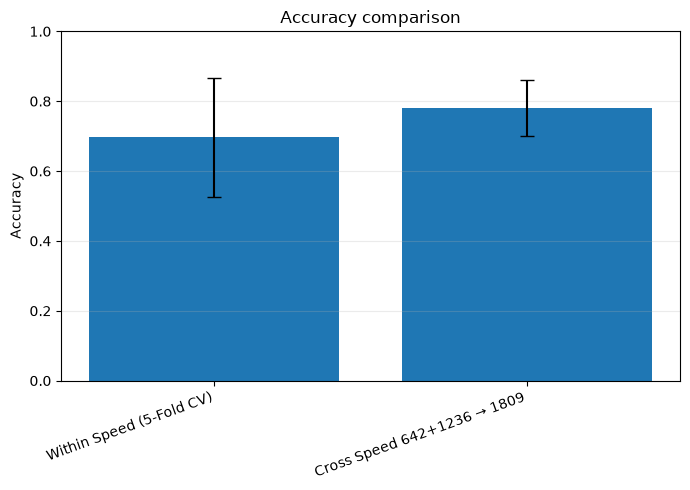

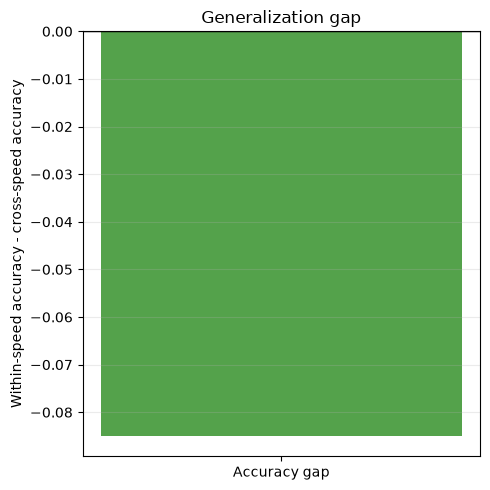

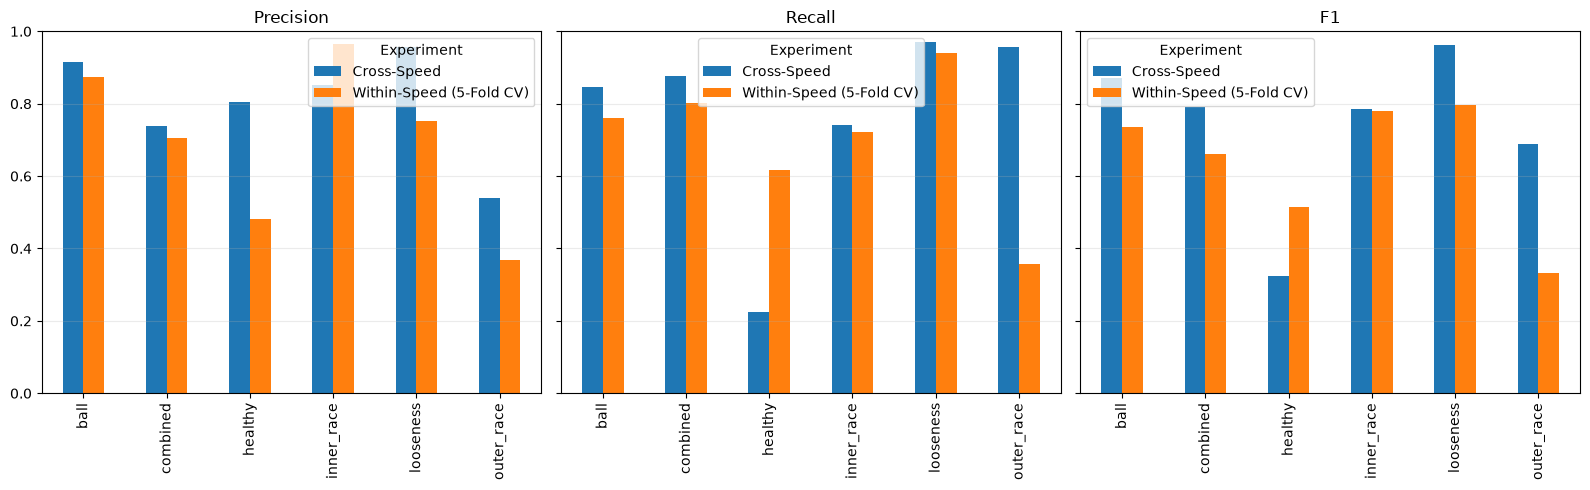

Best cross-speed class by F1: looseness (0.962)
Worst cross-speed class by F1: healthy (0.325)


In [24]:
baseline_results_df = pd.DataFrame(all_fold_metrics)

baseline_metrics = baseline_results_df.mean(numeric_only=True).to_dict()
baseline_std = baseline_results_df.std(numeric_only=True).to_dict()

cross_results_df = pd.DataFrame(cross_fold_metrics)

cross_metrics = (
    cross_results_df
    .mean(numeric_only=True)
    .to_dict()
)

cross_std = (
    cross_results_df
    .std(numeric_only=True)
    .to_dict()
)

generalization_gap = (
    baseline_metrics["accuracy"]
    - cross_metrics["accuracy"]
)

summary_df = pd.DataFrame([
    {
        "Experiment": "Within Speed (5-Fold CV)",
        "Accuracy": baseline_metrics["accuracy"],
        "Accuracy Std": baseline_std["accuracy"],

        "Weighted Precision": baseline_metrics["weighted_precision"],
        "Weighted Recall": baseline_metrics["weighted_recall"],
        "Weighted F1": baseline_metrics["weighted_f1"],

        "Macro Precision": baseline_metrics["macro_precision"],
        "Macro Recall": baseline_metrics["macro_recall"],
        "Macro F1": baseline_metrics["macro_f1"],

        "ROC AUC": baseline_metrics["roc_auc"],

        "Generalization Gap": np.nan,

        "Training Time": baseline_metrics["training_time_sec"],
        "Inference Time": baseline_metrics["inference_time_sec"],
    },
    {
    "Experiment": "Cross Speed 642+1236 → 1809",

    "Accuracy": cross_metrics["accuracy"],
    "Accuracy Std": cross_std["accuracy"],

    "Weighted Precision": cross_metrics["weighted_precision"],
    "Weighted Recall": cross_metrics["weighted_recall"],
    "Weighted F1": cross_metrics["weighted_f1"],

    "Macro Precision": cross_metrics["macro_precision"],
    "Macro Recall": cross_metrics["macro_recall"],
    "Macro F1": cross_metrics["macro_f1"],

    "ROC AUC": cross_metrics["roc_auc"],

    "Generalization Gap": generalization_gap,

    "Training Time": cross_metrics["training_time_sec"],
    "Inference Time": cross_metrics["inference_time_sec"],
},
])
summary_df.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)
display(summary_df)


def per_class_from_report(report_df, experiment_name):
    rows = []
    for cls in classes:
        if cls in report_df.index:
            rows.append({
                "Experiment": experiment_name,
                "Class": cls,
                "Precision": report_df.loc[cls, "precision"],
                "Recall": report_df.loc[cls, "recall"],
                "F1": report_df.loc[cls, "f1-score"],
            })
    return rows


# ======================================================
# Average classification report over 5 folds
# ======================================================

fold_reports = []

for report in all_fold_reports:

    df = report.copy()

    df["Class"] = df.index

    df = df[df["Class"].isin(classes)]

    fold_reports.append(
        df[
            [
                "Class",
                "precision",
                "recall",
                "f1-score",
            ]
        ]
    )

fold_report_df = pd.concat(fold_reports)

baseline_average = (
    fold_report_df
    .groupby("Class")
    .mean()
    .reset_index()
)

baseline_average["Experiment"] = "Within-Speed (5-Fold CV)"


cross_report_frames = []

for report in cross_fold_reports:
    df = report.copy()

    df["Class"] = df.index

    df = df[df["Class"].isin(classes)]

    cross_report_frames.append(
        df[
            [
                "Class",
                "precision",
                "recall",
                "f1-score",
            ]
        ]
    )

cross_report_df = pd.concat(
    cross_report_frames,
    ignore_index=True
)

cross_report = (
    cross_report_df
    .groupby("Class")[
        [
            "precision",
            "recall",
            "f1-score",
        ]
    ]
    .mean()
    .reset_index()
)

cross_report["Experiment"] = "Cross-Speed"

cross_report = cross_report.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
    }
)

cross_report = cross_report[
    cross_report["Class"].isin(classes)
]

cross_report["Experiment"] = "Cross-Speed"

cross_report = cross_report[
    [
        "Class",
        "Precision",
        "Recall",
        "F1",
        "Experiment",
    ]
]

baseline_average = baseline_average.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
    }
)

cross_report = cross_report.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1",
    }
)

per_class_df = pd.concat(
    [
        baseline_average,
        cross_report,
    ],
    ignore_index=True,
)

per_class_df.to_csv(
    RESULTS_DIR / "per_class_comparison.csv",
    index=False,
)

display(per_class_df)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(
    summary_df["Experiment"],
    summary_df["Accuracy"],
    yerr=summary_df["Accuracy Std"].fillna(0),
    capsize=5,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy comparison")
ax.grid(axis="y", alpha=0.25)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(["Accuracy gap"], [generalization_gap], color="#54a24b")
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Within-speed accuracy - cross-speed accuracy")
ax.set_title("Generalization gap")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "generalization_gap.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    pivot = per_class_df.pivot(index="Class", columns="Experiment", values=metric).reindex(classes)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "per_class_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

cross_f1 = per_class_df[per_class_df["Experiment"].eq("Cross-Speed")].set_index("Class")["F1"]
best_class = cross_f1.idxmax()
worst_class = cross_f1.idxmin()
print(f"Best cross-speed class by F1: {best_class} ({cross_f1.loc[best_class]:.3f})")
print(f"Worst cross-speed class by F1: {worst_class} ({cross_f1.loc[worst_class]:.3f})")

## Section 11.5 — Prepare Results for Section 12 (t-SNE)

In [25]:

if not all_fold_results:
    raise RuntimeError("No within-speed results available.")

if not cross_fold_results:
    raise RuntimeError("No cross-speed results available.")


# Select the last fold for visualization
baseline_result = all_fold_results[-1]
cross_speed_result = cross_fold_results[-1]


# Retrieve test DataFrames
baseline_test_df = baseline_result["test_df"]
cross_test_df = cross_speed_result["test_df"]


# Validate result structure
required_keys = {
    "model",
    "test_loader",
    "test_df",
}

for name, result in [
    ("Within Speed", baseline_result),
    ("Cross Speed", cross_speed_result),
]:

    missing_keys = required_keys - set(result.keys())

    if missing_keys:
        raise KeyError(
            f"{name} result is missing: {missing_keys}"
        )


print("Results prepared successfully.")
print(f"Within-speed test samples: {len(baseline_test_df)}")
print(f"Cross-speed test samples: {len(cross_test_df)}")

Results prepared successfully.
Within-speed test samples: 2337
Cross-speed test samples: 3901


## 12. Feature Embedding Visualization

Extract features: 100%|██████████| 63/63 [00:04<00:00, 14.87it/s]


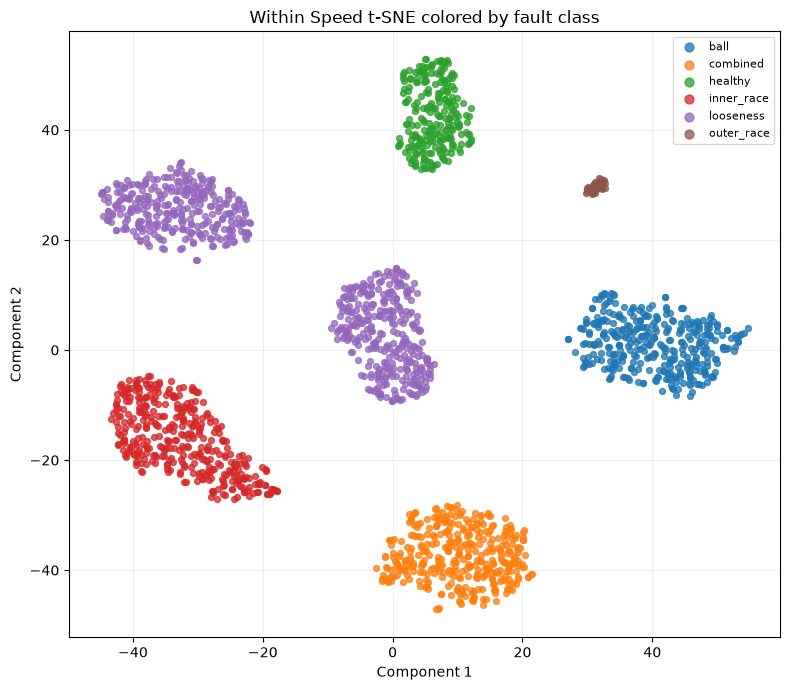

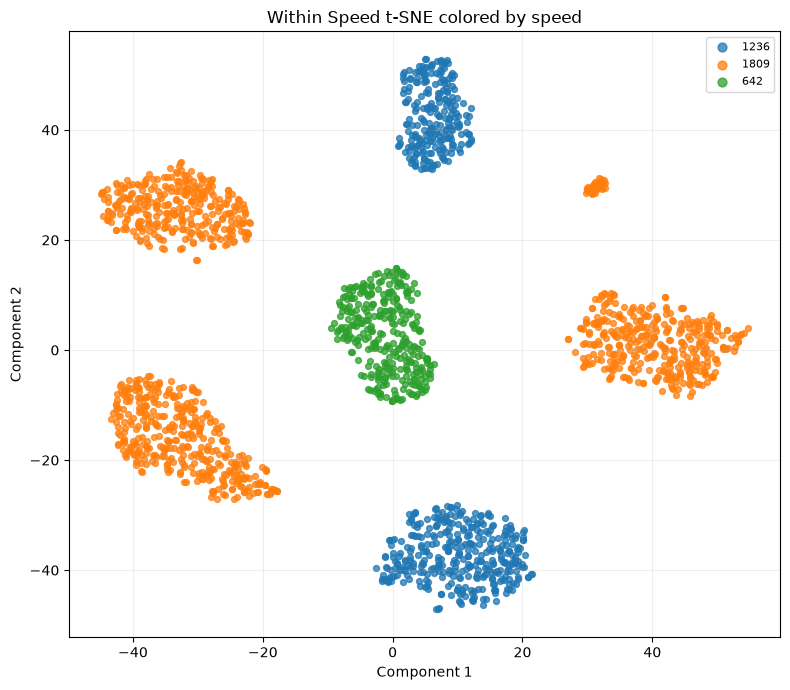

/home/arcues/Projects/IISA_2026/.venv/lib/python3.14/site-packages/umap/__init__.py:9: ImportWarning: Tensorflow not installed; ParametricUMAP will be unavailable
  warn(
/home/arcues/Projects/IISA_2026/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


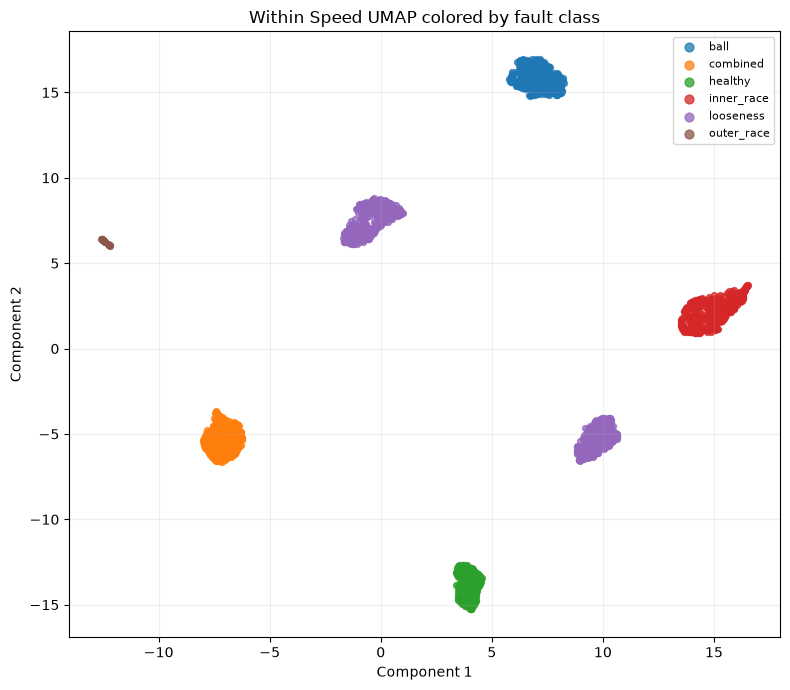

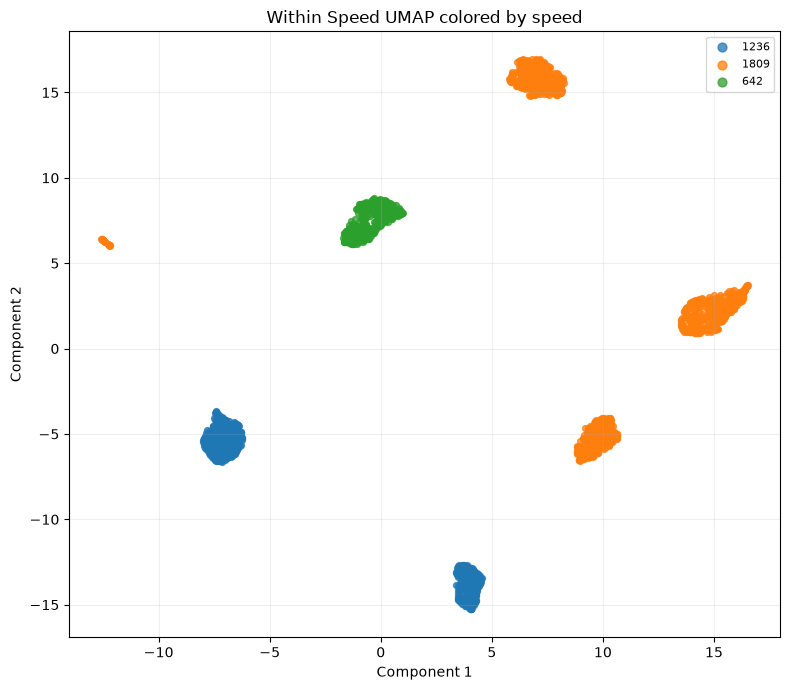

Extract features: 100%|██████████| 63/63 [00:04<00:00, 12.86it/s]


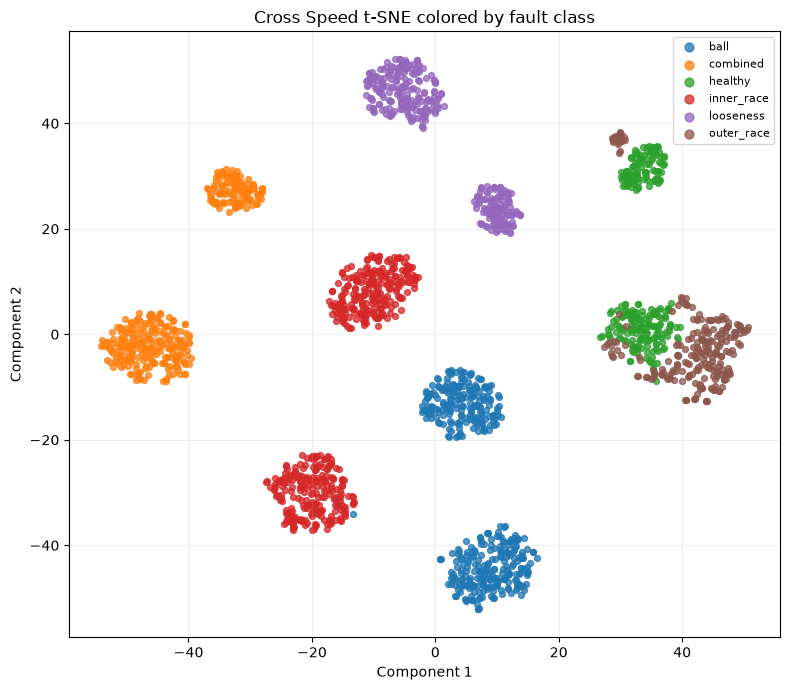

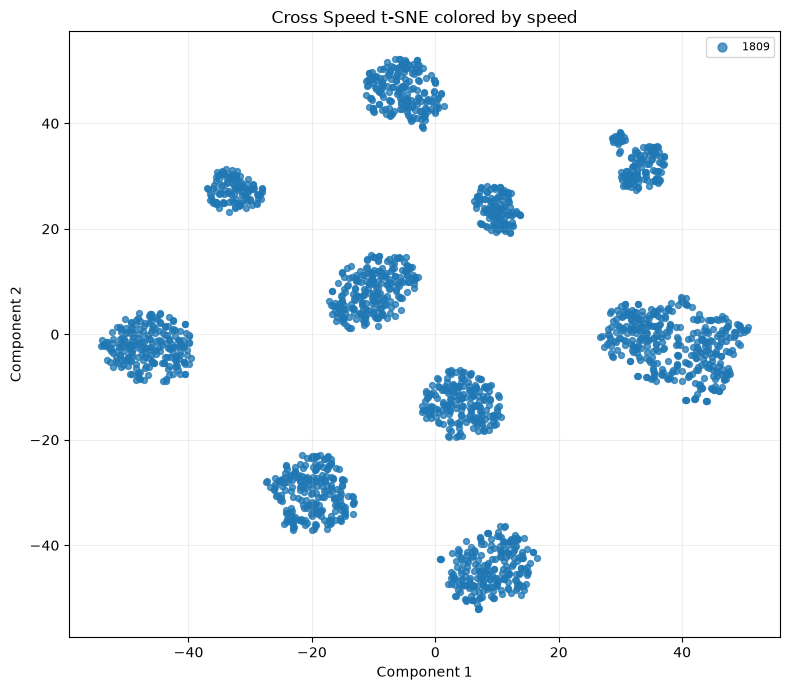

/home/arcues/Projects/IISA_2026/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


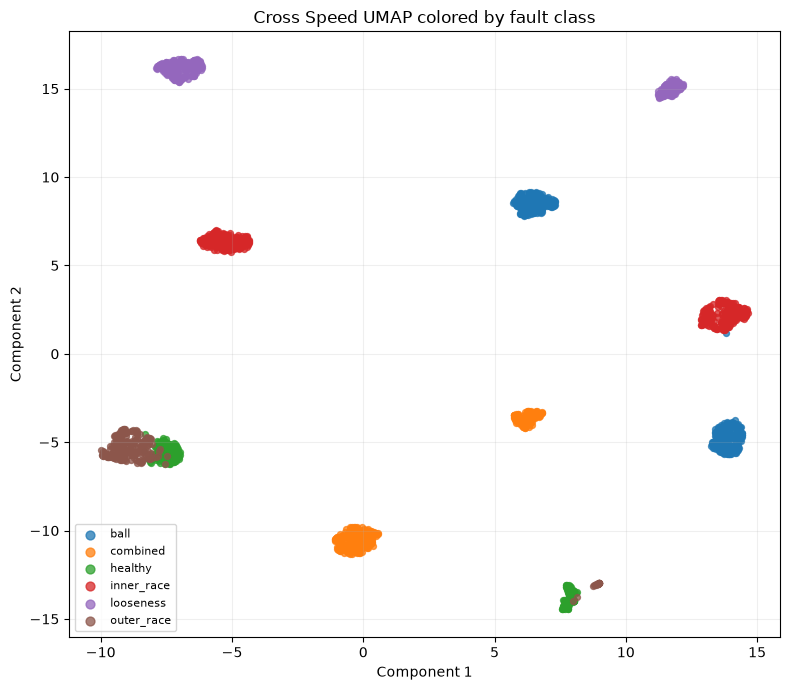

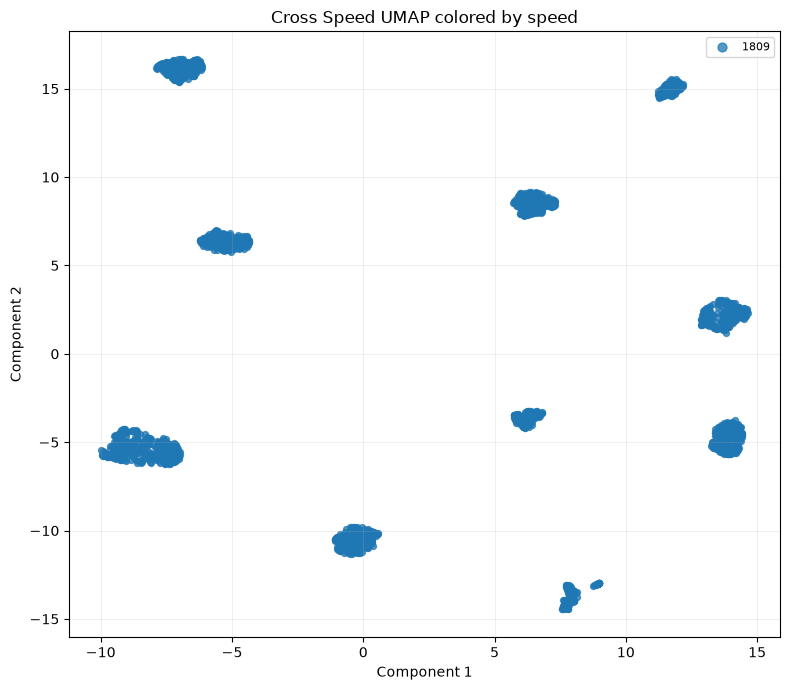

In [26]:
def extract_features(model, df: pd.DataFrame):
    if len(df) > CONFIG["max_embedding_samples"]:
        df = df.sample(CONFIG["max_embedding_samples"], random_state=SEED).reset_index(drop=True)
    loader = make_loader(df, "test", shuffle=False)
    features, labels, speeds = [], [], []

    def hook_fn(module, inputs, output):
        features.append(output.detach().cpu().flatten(start_dim=1).numpy())

    handle = model.avgpool.register_forward_hook(hook_fn)
    model.eval()
    with torch.no_grad():
        for images, batch_labels, metas in tqdm(loader, desc="Extract features"):
            images = images.to(DEVICE, non_blocking=True)
            _ = model(images)
            labels.extend([idx_to_class[int(i)] for i in batch_labels.numpy()])
            speeds.extend(list(metas["speed"]))
    handle.remove()
    feature_matrix = np.vstack(features) if features else np.empty((0, 0))
    meta_df = pd.DataFrame({"fault": labels, "speed": speeds})
    return feature_matrix, meta_df


def plot_embedding(embedding, meta_df, color_by, title, out_path):
    fig, ax = plt.subplots(figsize=(8, 7))
    categories = sorted(meta_df[color_by].astype(str).unique())
    cmap = plt.get_cmap("tab10")
    for i, category in enumerate(categories):
        mask = meta_df[color_by].astype(str).eq(category).values
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=18, alpha=0.75, label=category, color=cmap(i % 10))
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(markerscale=1.5, fontsize=8)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

for experiment_name, result, test_df in [
    ("Within Speed", baseline_result, baseline_test_df),
    ("Cross Speed", cross_speed_result, cross_test_df),
]:
    features, feature_meta = extract_features(
        result["model"],
        test_df.reset_index(drop=True),
    )

    if len(features) >= 3:
        perplexity = max(2, min(30, (len(features) - 1) // 3))

        tsne_embedding = TSNE(
            n_components=2,
            perplexity=perplexity,
            learning_rate="auto",
            init="pca",
            random_state=SEED,
        ).fit_transform(features)

        plot_embedding(
            tsne_embedding,
            feature_meta,
            "fault",
            f"{experiment_name} t-SNE colored by fault class",
            RESULTS_DIR / "tsne" / f"{slugify(experiment_name)}_tsne_by_fault.png",
        )

        plot_embedding(
            tsne_embedding,
            feature_meta,
            "speed",
            f"{experiment_name} t-SNE colored by speed",
            RESULTS_DIR / "tsne" / f"{slugify(experiment_name)}_tsne_by_speed.png",
        )

        if not QUICK_RUN:
            try:
                import umap.umap_ as umap
                UMAP_AVAILABLE = True
                UMAP_IMPORT_ERROR = None
            except Exception as exc:
                UMAP_AVAILABLE = False
                UMAP_IMPORT_ERROR = exc

        if UMAP_AVAILABLE:
            umap_embedding = umap.UMAP(
                n_components=2,
                random_state=SEED,
                n_neighbors=min(15, len(features) - 1),
            ).fit_transform(features)

            plot_embedding(
                umap_embedding,
                feature_meta,
                "fault",
                f"{experiment_name} UMAP colored by fault class",
                RESULTS_DIR / "umap" / f"{slugify(experiment_name)}_umap_by_fault.png",
            )

            plot_embedding(
                umap_embedding,
                feature_meta,
                "speed",
                f"{experiment_name} UMAP colored by speed",
                RESULTS_DIR / "umap" / f"{slugify(experiment_name)}_umap_by_speed.png",
            )
        else:
            print(f"UMAP is unavailable: {UMAP_IMPORT_ERROR}. Install umap-learn to enable UMAP plots.")
    else:
        print(f"Not enough feature vectors for {experiment_name}.")

In [21]:
print(result.keys())

dict_keys(['model', 'metrics', 'history', 'report', 'predictions', 'test_loader', 'test_df', 'checkpoint_path'])


## 13. Final Summary

In [27]:
summary_df = pd.read_csv(RESULTS_DIR / "summary.csv")
baseline_row = summary_df[
    summary_df["Experiment"].str.contains("Within")
].iloc[0]
cross_row = summary_df[summary_df["Experiment"].str.contains("Cross", case=False)].iloc[0]
total_training_time = summary_df["Training Time"].sum()
total_inference_time = summary_df["Inference Time"].sum()

print("=" * 38)
print("Bearing Fault Diagnosis Summary")
print("=" * 38)
print("\nDataset")
print("-------")
print(f"Number of recordings : {len(recordings_df)}")
print(f"Number of segments   : {len(segments_df)}")
print(f"Fault classes        : {', '.join(classes)}")
print(f"Acquisition methods  : {', '.join(sorted(recordings_df['acquisition'].unique()))}")
print(f"Speeds               : {', '.join(sorted(recordings_df['speed'].unique()))}")

print("\nExperiment 1 (Within-Speed 5-Fold CV)")
print("--------------------------------------")
print(f"Accuracy            : {baseline_row['Accuracy']:.4f} ± {baseline_row['Accuracy Std']:.4f}")
print(f"Weighted Precision  : {baseline_row['Weighted Precision']:.4f}")
print(f"Weighted Recall     : {baseline_row['Weighted Recall']:.4f}")
print(f"Weighted F1-score   : {baseline_row['Weighted F1']:.4f}")
print(f"Macro F1-score      : {baseline_row['Macro F1']:.4f}")
print(f"ROC-AUC             : {baseline_row['ROC AUC']:.4f}")

print("\nExperiment 2 (Cross-Speed 4-Fold CV)")
print("------------------------------------")
print(f"Accuracy            : {cross_row['Accuracy']:.4f} ± {cross_row['Accuracy Std']:.4f}")
print(f"Weighted Precision  : {cross_row['Weighted Precision']:.4f}")
print(f"Weighted Recall     : {cross_row['Weighted Recall']:.4f}")
print(f"Weighted F1-score   : {cross_row['Weighted F1']:.4f}")
print(f"Macro F1-score      : {cross_row['Macro F1']:.4f}")
print(f"ROC-AUC             : {cross_row['ROC AUC']:.4f}")

print("\nGeneralization Gap")
print("------------------")
print(f"Accuracy Gap : {generalization_gap:.4f}")
print(f"Worst class  : {worst_class}")
print(f"Best class   : {best_class}")

print(f"\nTraining Time : {total_training_time:.2f} sec")
print(f"Inference Time: {total_inference_time:.2f} sec")
print(f"GPU Used      : {DEVICE.type == 'cuda'} ({DEVICE})")
print("=" * 38)

Bearing Fault Diagnosis Summary

Dataset
-------
Number of recordings : 36
Number of segments   : 11703
Fault classes        : ball, combined, healthy, inner_race, looseness, outer_race
Acquisition methods  : with_stethoscope, without_stethoscope
Speeds               : 1236, 1809, 642

Experiment 1 (Within-Speed 5-Fold CV)
--------------------------------------
Accuracy            : 0.6968 ± 0.1700
Weighted Precision  : 0.7678
Weighted Recall     : 0.6968
Weighted F1-score   : 0.6705
Macro F1-score      : 0.6366
ROC-AUC             : 0.9371

Experiment 2 (Cross-Speed 4-Fold CV)
------------------------------------
Accuracy            : 0.7818 ± 0.0800
Weighted Precision  : 0.8192
Weighted Recall     : 0.7818
Weighted F1-score   : 0.7618
Macro F1-score      : 0.7373
ROC-AUC             : 0.9508

Generalization Gap
------------------
Accuracy Gap : -0.0850
Worst class  : healthy
Best class   : looseness

Training Time : 238.69 sec
Inference Time: 13.08 sec
GPU Used      : True (cuda)


## Required Python Packages

Install the required packages with:

```bash
pip install numpy pandas scipy PyWavelets matplotlib scikit-learn torch torchvision tqdm umap-learn pillow ipykernel nbconvert
```